# Brain Tumor MRI Classification — Hybrid Multi-Model Ensemble

**Backbones fused in this project:** Custom CNN &bull; EfficientNetB3 &bull; VGG16 &bull; ResNet50 &bull; DenseNet121 &bull; MedicalNet-inspired residual network

## What this notebook does
This is a full rewrite of the original single-VGG16 prototype into a **hybrid, multi-branch deep learning system** for classifying brain MRI scans into four classes: `glioma`, `meningioma`, `notumor`, `pituitary`.

Instead of relying on one pretrained network, six independent feature-extraction branches look at the **same input image** and their learned representations are **fused** into one classifier head. The idea is that each architecture has different inductive biases (depth, receptive field, connectivity pattern), so combining them can capture complementary patterns in the MRI textures that any single network might miss.

**The six branches:**
1. **Custom CNN** — a small from-scratch convolutional network, trained only on this dataset, with no external bias.
2. **EfficientNetB3** — compound-scaled efficient architecture, ImageNet pretrained.
3. **VGG16** — classic deep CNN with small 3x3 filters, ImageNet pretrained (this was the original project's only model).
4. **ResNet50** — residual connections that ease gradient flow in very deep networks, ImageNet pretrained.
5. **DenseNet121** — densely-connected blocks that encourage feature reuse, ImageNet pretrained.
6. **MedicalNet-inspired branch** — see the note below.

> **Honest note on "MedicalNet":** the real MedicalNet / Med3D project is a set of **3D ResNets pretrained on CT volumes in PyTorch** (designed for volumetric scans, not single 2D JPEG/PNG slices, and not natively loadable inside a Keras/TensorFlow graph). Since this dataset is 2D MRI slices, we cannot legitimately drop in Med3D's actual pretrained 3D weights here without a separate PyTorch pipeline and 3D volume data. To stay technically honest, this notebook instead includes a **2D residual CNN branch inspired by MedicalNet's architecture family** (stacked residual blocks, similar receptive-field growth), trained from scratch alongside the rest of the hybrid model. The final "Optional — True 3D MedicalNet" section at the end explains exactly how to plug in the real PyTorch Med3D weights if you later obtain 3D volumetric data.

## Notebook map
1. Environment setup & imports
2. Configuration
3. Data loading & train/val/test split
4. Exploratory data visualization
5. tf.data input pipeline (shared raw pixels + per-backbone preprocessing)
6. Branch builders (Custom CNN, VGG16, ResNet50, DenseNet121, EfficientNetB3, MedicalNet-inspired)
7. Hybrid fusion model
8. Class weights & callbacks
9. Two-phase training (frozen backbones -> fine-tune)
10. Training curves
11. Evaluation on held-out test set (classification report, confusion matrix, ROC-AUC)
12. Individual backbone baselines (for comparison + reused later as an ensemble)
13. Weighted soft-voting ensemble (Approach B, no giant model needed)
14. Grad-CAM explainability
15. Save / load the hybrid model
16. Single-image inference tool
17. Batch inference demo
18. Appendix: plugging in a true 3D MedicalNet branch

## 1. Environment Setup & Imports

In [1]:
!pip install tensorflow scikit-learn matplotlib seaborn pillow

In [2]:
import os
import glob
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
from tensorflow.keras.applications import vgg16, resnet50, densenet, efficientnet

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
)
from sklearn.preprocessing import label_binarize

print("TensorFlow version:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("GPUs detected:", gpus)
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)


TensorFlow version: 2.20.0
GPUs detected: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Configuration

In [3]:
# ---- Reproducibility ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ---- Paths (EDIT THESE for your machine / Kaggle / Colab) ----
# Expected layout (same as the original project):
#   train_dir/<class_name>/*.jpg
#   test_dir/<class_name>/*.jpg
train_dir = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training"
test_dir  = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing"

# ---- Image / training config ----
IMAGE_SIZE   = 224          # shared input size for ALL six branches
NUM_CHANNELS = 3
BATCH_SIZE   = 16           # 6 backbones running together is memory-heavy; lower this if you hit OOM
PROJ_DIM     = 256          # dimensionality each branch is projected to before fusion
VAL_SPLIT    = 0.15         # carved out of the training folder (stratified)

# ---- Class names (alphabetical, matches os.listdir order in most Kaggle copies of this dataset) ----
CLASS_NAMES = sorted(os.listdir(train_dir)) if os.path.isdir(train_dir) else \
    ['glioma', 'meningioma', 'notumor', 'pituitary']
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
print("Classes:", CLASS_NAMES)

# ---- Optional: mixed precision to cut memory use on modern GPUs ----
USE_MIXED_PRECISION = False
if USE_MIXED_PRECISION:
    tf.keras.mixed_precision.set_global_policy('mixed_float16')
    print("Mixed precision enabled:", tf.keras.mixed_precision.global_policy())


Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


## 3. Data Loading & Train / Val / Test Split

In [4]:
def collect_paths_labels(root_dir):
    paths, labels = [], []
    for label in os.listdir(root_dir):
        class_dir = os.path.join(root_dir, label)
        if not os.path.isdir(class_dir):
            continue
        for fname in os.listdir(class_dir):
            paths.append(os.path.join(class_dir, fname))
            labels.append(label)
    return paths, labels

all_train_paths, all_train_labels = collect_paths_labels(train_dir)
test_paths, test_labels = collect_paths_labels(test_dir)

# Stratified split of the training folder into train / validation.
# (The original notebook referenced val_paths/val_labels without ever creating
#  them — this fixes that bug properly with a real stratified split.)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    all_train_paths,
    all_train_labels,
    test_size=VAL_SPLIT,
    stratify=all_train_labels,
    random_state=SEED,
)

print(f"Train images:      {len(train_paths)}")
print(f"Validation images: {len(val_paths)}")
print(f"Test images:       {len(test_paths)}")


Train images:      4760
Validation images: 840
Test images:       1600


## 4. Exploratory Data Visualization

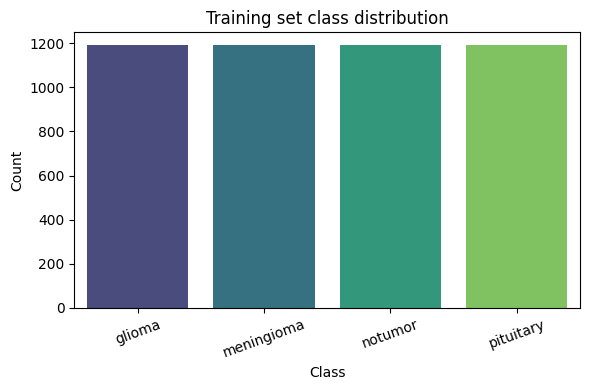

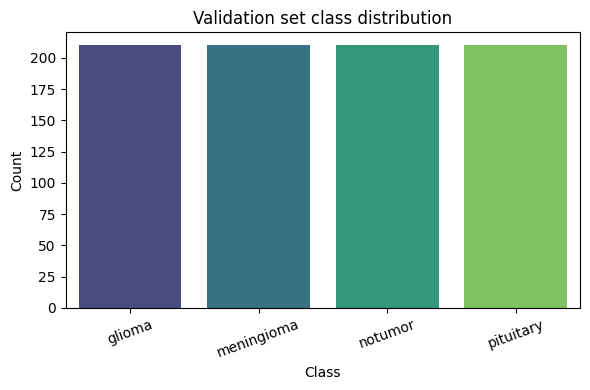

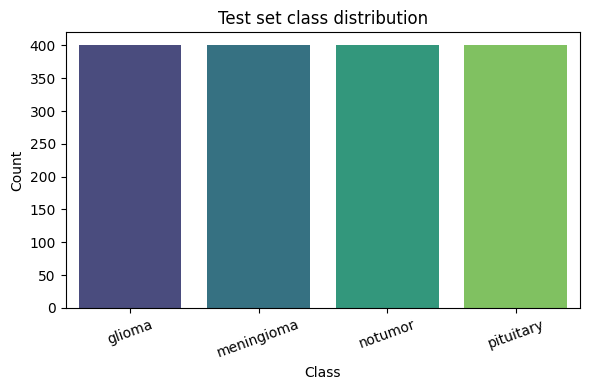

In [5]:
def plot_class_distribution(labels, title):
    values, counts = np.unique(labels, return_counts=True)
    plt.figure(figsize=(6, 4))
    sns.barplot(x=values, y=counts, hue=values, palette='viridis', legend=False)
    plt.title(title)
    plt.ylabel("Count")
    plt.xlabel("Class")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

plot_class_distribution(train_labels, "Training set class distribution")
plot_class_distribution(val_labels,   "Validation set class distribution")
plot_class_distribution(test_labels,  "Test set class distribution")


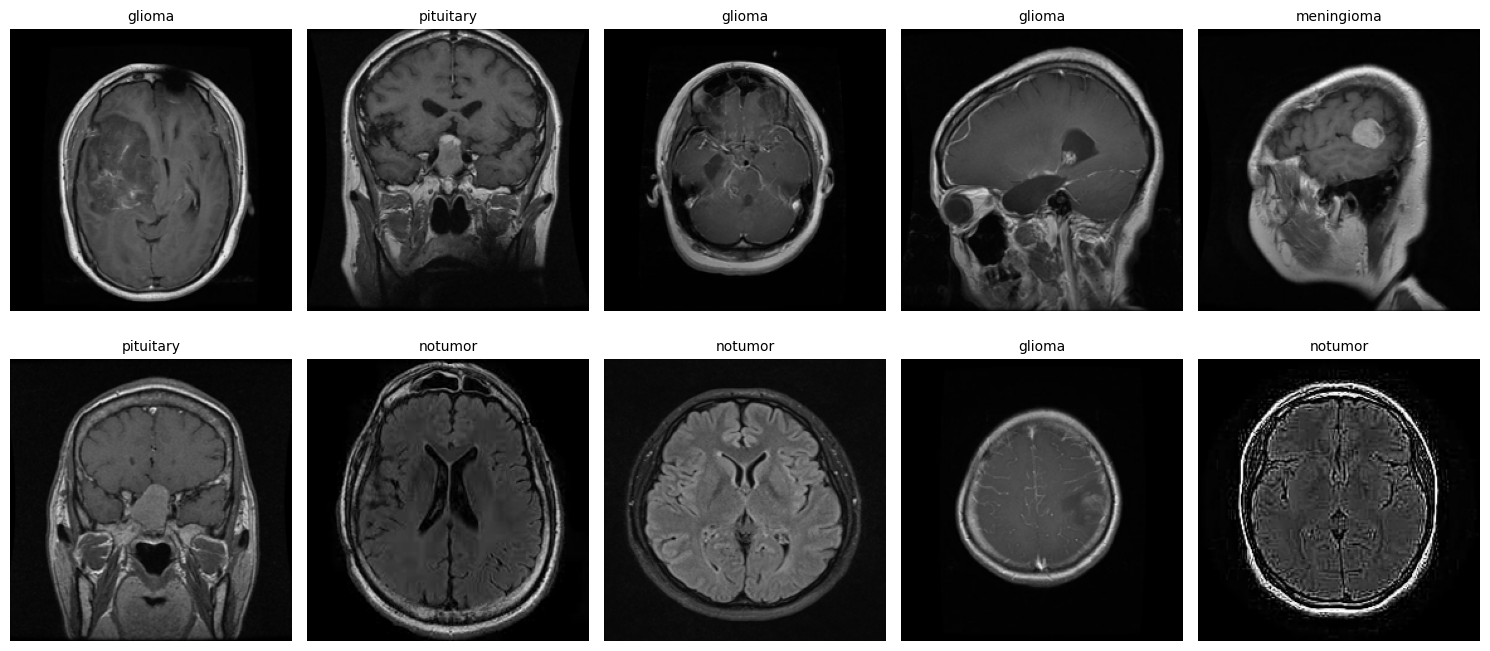

In [6]:
# Sample grid of images
random_indices = random.sample(range(len(train_paths)), 10)
fig, axes = plt.subplots(2, 5, figsize=(15, 7))
axes = axes.ravel()
for i, idx in enumerate(random_indices):
    img = Image.open(train_paths[idx]).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))
    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(train_labels[idx], fontsize=10)
plt.tight_layout()
plt.show()


## 5. tf.data Input Pipeline

Every branch shares **one raw image tensor** (pixels in `[0, 255]`, resized to `IMAGE_SIZE`).
Backbone-specific normalization (VGG "caffe" style, ResNet "caffe" style, DenseNet "torch" style,
EfficientNet's built-in rescaling) happens **inside the model itself**, as the first step of each
branch. This keeps one clean input pipeline while still feeding every backbone the exact
preprocessing it was pretrained with.

In [7]:
AUTOTUNE = tf.data.AUTOTUNE

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.04),
    layers.RandomZoom(0.08),
    layers.RandomContrast(0.10),
], name="data_augmentation")

def _load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (IMAGE_SIZE, IMAGE_SIZE))
    image = tf.cast(image, tf.float32)  # kept in [0, 255]; branches handle their own scaling
    return image, label

def make_dataset(paths, labels, training=False, batch_size=BATCH_SIZE):
    label_ids = [CLASS_TO_IDX[l] for l in labels]
    ds = tf.data.Dataset.from_tensor_slices((list(paths), label_ids))
    if training:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(_load_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds   = make_dataset(val_paths,   val_labels,   training=False)
test_ds  = make_dataset(test_paths,  test_labels,  training=False)

I0000 00:00:1792848417.247337      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792848417.251121      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


## 6. Branch Builders

Each function below returns a **feature tensor projected to `PROJ_DIM` dimensions**, so that all
six branches contribute equally-sized vectors to the fusion layer regardless of their native
feature size (VGG16=512, ResNet50=2048, DenseNet121=1024, EfficientNetB3=1536).

In [8]:
def build_projection_head(x, name, proj_dim=PROJ_DIM, dropout=0.3):
    """Shrinks / standardizes a branch's raw feature vector before fusion."""
    x = layers.Dense(proj_dim, activation='relu', name=f'{name}_proj_dense')(x)
    x = layers.BatchNormalization(name=f'{name}_proj_bn')(x)
    x = layers.Dropout(dropout, name=f'{name}_proj_drop')(x)
    return x


def build_pretrained_branch(name, application_fn, preprocess_fn, input_tensor, proj_dim=PROJ_DIM):
    """Wraps a Keras Applications backbone: preprocess -> ImageNet backbone -> GAP -> projection.
    All backbone layers start frozen; call unfreeze_backbones() later for fine-tuning.
    Returns (projected_feature_tensor, base_model) so it can be fine-tuned afterwards.
    """
    preprocessed = layers.Lambda(preprocess_fn, name=f'{name}_preprocess')(input_tensor)
    base = application_fn(
        include_top=False,
        weights='imagenet',
        input_tensor=preprocessed,
        pooling='avg',
    )
    base._name = f'{name}_backbone'
    for layer in base.layers:
        layer.trainable = False
    feat = build_projection_head(base.output, name, proj_dim)
    return feat, base


def build_custom_cnn_branch(input_tensor, proj_dim=PROJ_DIM):
    """From-scratch CNN — no ImageNet bias, learns purely from MRI textures."""
    x = layers.Rescaling(1. / 255, name='customcnn_rescale')(input_tensor)
    for filters in (32, 64, 128, 256):
        x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    return build_projection_head(x, 'customcnn', proj_dim)


def _residual_block(x, filters, stride=1, name=''):
    shortcut = x
    y = layers.Conv2D(filters, 3, strides=stride, padding='same', use_bias=False, name=f'{name}_conv1')(x)
    y = layers.BatchNormalization(name=f'{name}_bn1')(y)
    y = layers.ReLU(name=f'{name}_relu1')(y)
    y = layers.Conv2D(filters, 3, strides=1, padding='same', use_bias=False, name=f'{name}_conv2')(y)
    y = layers.BatchNormalization(name=f'{name}_bn2')(y)
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride, padding='same', use_bias=False, name=f'{name}_proj')(shortcut)
        shortcut = layers.BatchNormalization(name=f'{name}_projbn')(shortcut)
    out = layers.Add(name=f'{name}_add')([y, shortcut])
    out = layers.ReLU(name=f'{name}_out')(out)
    return out


def build_medicalnet_inspired_branch(input_tensor, proj_dim=PROJ_DIM):
    """2D residual network inspired by MedicalNet/Med3D's block design (see markdown note above
    on why we don't load the real 3D pretrained weights for a 2D-slice dataset)."""
    x = layers.Rescaling(1. / 255, name='mednet_rescale')(input_tensor)
    x = layers.Conv2D(32, 7, strides=2, padding='same', use_bias=False, name='mednet_stem_conv')(x)
    x = layers.BatchNormalization(name='mednet_stem_bn')(x)
    x = layers.ReLU(name='mednet_stem_relu')(x)
    x = layers.MaxPooling2D(3, strides=2, padding='same', name='mednet_stem_pool')(x)
    x = _residual_block(x, 32,  stride=1, name='mednet_block1a')
    x = _residual_block(x, 32,  stride=1, name='mednet_block1b')
    x = _residual_block(x, 64,  stride=2, name='mednet_block2a')
    x = _residual_block(x, 64,  stride=1, name='mednet_block2b')
    x = _residual_block(x, 128, stride=2, name='mednet_block3a')
    x = _residual_block(x, 128, stride=1, name='mednet_block3b')
    x = layers.GlobalAveragePooling2D(name='mednet_gap')(x)
    return build_projection_head(x, 'mednet', proj_dim)


## 7. Hybrid Fusion Model

In [9]:
def build_pretrained_branch(
    model_name,
    Backbone,
    preprocess_fn,
    inp,
    proj_dim
):
    # Get image size from main input
    image_size = inp.shape[1]

    # Create a separate input for this backbone
    branch_input = layers.Input(
        shape=(image_size, image_size, 3),
        name=f"{model_name}_input"
    )

    # Preprocessing
    x = layers.Lambda(
        lambda z: preprocess_fn(z),
        name=f"{model_name}_preprocess"
    )(branch_input)

    # Pretrained backbone
    base = Backbone(
        include_top=False,
        weights="imagenet",
        input_shape=(image_size, image_size, 3),
        pooling="avg"
    )

    # Freeze pretrained backbone
    base.trainable = False

    # Extract features
    x = base(x)

    # Projection
    x = layers.Dense(
        proj_dim,
        activation="relu",
        name=f"{model_name}_projection"
    )(x)

    x = layers.BatchNormalization(
        name=f"{model_name}_projection_bn"
    )(x)

    x = layers.Dropout(
        0.20,
        name=f"{model_name}_projection_dropout"
    )(x)

    # Make this branch a separate nested model
    branch_model = models.Model(
        inputs=branch_input,
        outputs=x,
        name=f"{model_name}_branch"
    )

    # Connect the branch model to the main input
    branch_output = branch_model(inp)

    return branch_output, base

# HYBRID MODEL
def build_hybrid_model(
    image_size=IMAGE_SIZE,
    num_classes=NUM_CLASSES,
    proj_dim=PROJ_DIM
):
    inp = layers.Input(
        shape=(image_size, image_size, 3),
        name="input_image"
    )

    backbones = {}

    # Custom branches
    custom_feat = build_custom_cnn_branch(
        inp,
        proj_dim
    )

    mednet_feat = build_medicalnet_inspired_branch(
        inp,
        proj_dim
    )

    # Pretrained branches
    vgg_feat, backbones["vgg16"] = build_pretrained_branch(
        "vgg16",
        vgg16.VGG16,
        vgg16.preprocess_input,
        inp,
        proj_dim
    )

    resnet_feat, backbones["resnet50"] = build_pretrained_branch(
        "resnet50",
        resnet50.ResNet50,
        resnet50.preprocess_input,
        inp,
        proj_dim
    )

    dense_feat, backbones["densenet121"] = build_pretrained_branch(
        "densenet121",
        densenet.DenseNet121,
        densenet.preprocess_input,
        inp,
        proj_dim
    )

    eff_feat, backbones["efficientnetb3"] = build_pretrained_branch(
        "efficientnetb3",
        efficientnet.EfficientNetB3,
        efficientnet.preprocess_input,
        inp,
        proj_dim
    )

    # Feature fusion
    fused = layers.Concatenate(
        name="fusion_concat"
    )([
        custom_feat,
        mednet_feat,
        vgg_feat,
        resnet_feat,
        dense_feat,
        eff_feat
    ])

    # Fusion classifier
    x = layers.Dense(
        512,
        activation="relu",
        name="fusion_dense1"
    )(fused)

    x = layers.BatchNormalization(
        name="fusion_bn1"
    )(x)

    x = layers.Dropout(
        0.4,
        name="fusion_drop1"
    )(x)

    x = layers.Dense(
        256,
        activation="relu",
        name="fusion_dense2"
    )(x)

    x = layers.Dropout(
        0.3,
        name="fusion_drop2"
    )(x)

    out = layers.Dense(
        num_classes,
        activation="softmax",
        dtype="float32",
        name="predictions"
    )(x)

    # Final model
    model = models.Model(
        inputs=inp,
        outputs=out,
        name="Hybrid_MultiModel_BrainTumor"
    )

    return model, backbones

# BUILD MODEL
hybrid_model, backbones = build_hybrid_model()

hybrid_model.summary(show_trainable=True)

print(
    "\nTotal params:",
    f"{hybrid_model.count_params():,}"
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Hybrid_MultiModel_BrainTumor"

┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)      ┃ Output Shape    ┃   Param # ┃ Connected to   ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ input_image       │ (None, 224,     │         0 │ -              │   -   │
│ (InputLayer)      │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ mednet_rescale    │ (None, 224,     │         0 │ input_image[0… │   -   │
│ (Rescaling)       │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ mednet_stem_conv  │ (None, 112,     │     4,704 │ mednet_rescal… │   Y   │
│ (Conv2D)          │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ mednet_stem_bn    │ (None, 112,     │       128 │ mednet_stem_c… │   Y   │
│ (BatchNormalizat… │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ mednet_stem_relu  │ (None, 112,     │         0 │ mednet_stem_b… │   -   │
│ (ReLU)            │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ mednet_stem_pool  │ (None, 56, 56,  │         0 │ mednet_stem_r… │   -   │
│ (MaxPooling2D)    │ 32)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ mednet_block1a_c… │ (None, 56, 56,  │     9,216 │ mednet_stem_p… │   Y   │
│ (Conv2D)          │ 32)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ mednet_block1a_b… │ (None, 56, 56,  │       128 │ mednet_block1… │   Y   │
│ (BatchNormalizat… │ 32)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ mednet_block1a_r… │ (None, 56, 56,  │         0 │ mednet_block1… │   -   │
│ (ReLU)            │ 32)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ mednet_block1a_c… │ (None, 56, 56,  │     9,216 │ mednet_block1… │   Y   │
│ (Conv2D)          │ 32)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ mednet_block1a_b… │ (None, 56, 56,  │       128 │ mednet_block1… │   Y   │
│ (BatchNormalizat… │ 32)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ mednet_block1a_a… │ (None, 56, 56,  │         0 │ mednet_block1… │   -   │
│ (Add)             │ 32)             │           │ mednet_stem_p… │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ mednet_block1a_o… │ (None, 56, 56,  │         0 │ mednet_block1… │   -   │
│ (ReLU)            │ 32)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ mednet_block1b_c… │ (None, 56, 56,  │     9,216 │ mednet_block1… │   Y   │
│ (Conv2D)          │ 32)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ mednet_block1b_b… │ (None, 56, 56,  │       128 │ mednet_block1… │   Y   │
│ (BatchNormalizat… │ 32)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ mednet_block1b_r… │ (None, 56, 56,  │         0 │ mednet_block1… │   -   │
│ (ReLU)            │ 32)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ mednet_block1b_c… │ (None, 56, 56,  │     9,216 │ mednet_block1… │   Y 

 Total params: 59,553,235 (227.18 MB)

 Trainable params: 3,422,500 (13.06 MB)

 Non-trainable params: 56,130,735 (214.12 MB)


Total params: 59,553,235


In [10]:
def unfreeze_backbones(backbones, n_layers=10):
    """Unfreezes the last n_layers of every pretrained backbone (BatchNorm layers stay frozen
    so their running statistics aren't disturbed by small fine-tuning batches)."""
    for name, base in backbones.items():
        count = 0
        for layer in base.layers[-n_layers:]:
            if not isinstance(layer, layers.BatchNormalization):
                layer.trainable = True
                count += 1
        print(f"{name}: unfroze {count} layers")


## 8. Class Weights & Callbacks

In [11]:
train_label_ids = np.array([CLASS_TO_IDX[l] for l in train_labels])
class_weight_values = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=train_label_ids,
)
class_weights = dict(enumerate(class_weight_values))
print("Class weights:", {CLASS_NAMES[i]: round(w, 3) for i, w in class_weights.items()})

def make_callbacks(checkpoint_path):
    return [
        callbacks.EarlyStopping(monitor='val_accuracy', patience=6, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7),
        callbacks.ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True),
    ]


Class weights: {'glioma': np.float64(1.0), 'meningioma': np.float64(1.0), 'notumor': np.float64(1.0), 'pituitary': np.float64(1.0)}


## 9. Two-Phase Training

**Phase 1 — Warm-up:** all five ImageNet backbones stay fully frozen. Only the from-scratch
branches (Custom CNN, MedicalNet-inspired) and the fusion head learn, so the randomly-initialized
layers don't send noisy gradients backward into the pretrained weights.

**Phase 2 — Fine-tuning:** the last few layers of each pretrained backbone are unfrozen and the
whole model is trained further at a much lower learning rate.

In [12]:
PHASE1_EPOCHS = 20
PHASE2_EPOCHS = 30

hybrid_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

history1 = hybrid_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=PHASE1_EPOCHS,
    class_weight=class_weights,
    callbacks=make_callbacks('best_hybrid_phase1.keras'),
)


Epoch 1/20


2026-10-24 13:28:27.522024: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 13:28:27.660314: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 13:28:28.039940: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 13:28:28.189707: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 13:28:28.339716: E external/local_xla/xla/stream_

297/298 ━━━━━━━━━━━━━━━━━━━━ 0s 517ms/step - accuracy: 0.6299 - loss: 1.0406

2026-10-24 13:32:03.577064: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 13:32:03.714996: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 13:32:04.052357: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 13:32:04.202297: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 13:32:05.007063: E external/local_xla/xla/stream_

298/298 ━━━━━━━━━━━━━━━━━━━━ 402s 963ms/step - accuracy: 0.7275 - loss: 0.7558 - val_accuracy: 0.8143 - val_loss: 0.4672 - learning_rate: 1.0000e-04
Epoch 2/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 115s 385ms/step - accuracy: 0.8227 - loss: 0.4832 - val_accuracy: 0.8952 - val_loss: 0.2912 - learning_rate: 1.0000e-04
Epoch 3/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 115s 385ms/step - accuracy: 0.8666 - loss: 0.3684 - val_accuracy: 0.9202 - val_loss: 0.2087 - learning_rate: 1.0000e-04
Epoch 4/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 110s 370ms/step - accuracy: 0.8840 - loss: 0.3115 - val_accuracy: 0.9000 - val_loss: 0.2477 - learning_rate: 1.0000e-04
Epoch 5/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 110s 369ms/step - accuracy: 0.8962 - loss: 0.2986 - val_accuracy: 0.8810 - val_loss: 0.2964 - learning_rate: 1.0000e-04
Epoch 6/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 110s 369ms/step - accuracy: 0.9141 - loss: 0.2344 - val_accuracy: 0.8750 - val_loss: 0.3547 - learning_rate: 1.0000e-04
Epoch 7/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 110s 369ms/

In [13]:
unfreeze_backbones(backbones, n_layers=10)

hybrid_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),  # much lower LR for fine-tuning
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

history2 = hybrid_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=PHASE1_EPOCHS + PHASE2_EPOCHS,
    initial_epoch=history1.epoch[-1] + 1,
    class_weight=class_weights,
    callbacks=make_callbacks('best_hybrid_phase2.keras'),
)


vgg16: unfroze 10 layers
resnet50: unfroze 7 layers
densenet121: unfroze 7 layers
efficientnetb3: unfroze 8 layers
Epoch 18/50
298/298 ━━━━━━━━━━━━━━━━━━━━ 339s 796ms/step - accuracy: 0.9332 - loss: 0.1894 - val_accuracy: 0.9381 - val_loss: 0.1656 - learning_rate: 1.0000e-05
Epoch 19/50
298/298 ━━━━━━━━━━━━━━━━━━━━ 162s 450ms/step - accuracy: 0.9338 - loss: 0.1787 - val_accuracy: 0.9155 - val_loss: 0.2187 - learning_rate: 1.0000e-05
Epoch 20/50
298/298 ━━━━━━━━━━━━━━━━━━━━ 138s 462ms/step - accuracy: 0.9355 - loss: 0.1840 - val_accuracy: 0.9405 - val_loss: 0.1607 - learning_rate: 1.0000e-05
Epoch 21/50
298/298 ━━━━━━━━━━━━━━━━━━━━ 134s 449ms/step - accuracy: 0.9412 - loss: 0.1566 - val_accuracy: 0.9012 - val_loss: 0.2602 - learning_rate: 1.0000e-05
Epoch 22/50
298/298 ━━━━━━━━━━━━━━━━━━━━ 133s 447ms/step - accuracy: 0.9462 - loss: 0.1513 - val_accuracy: 0.8452 - val_loss: 0.4517 - learning_rate: 1.0000e-05
Epoch 23/50
298/298 ━━━━━━━━━━━━━━━━━━━━ 134s 448ms/step - accuracy: 0.9441 - lo

## 10. Training Curves

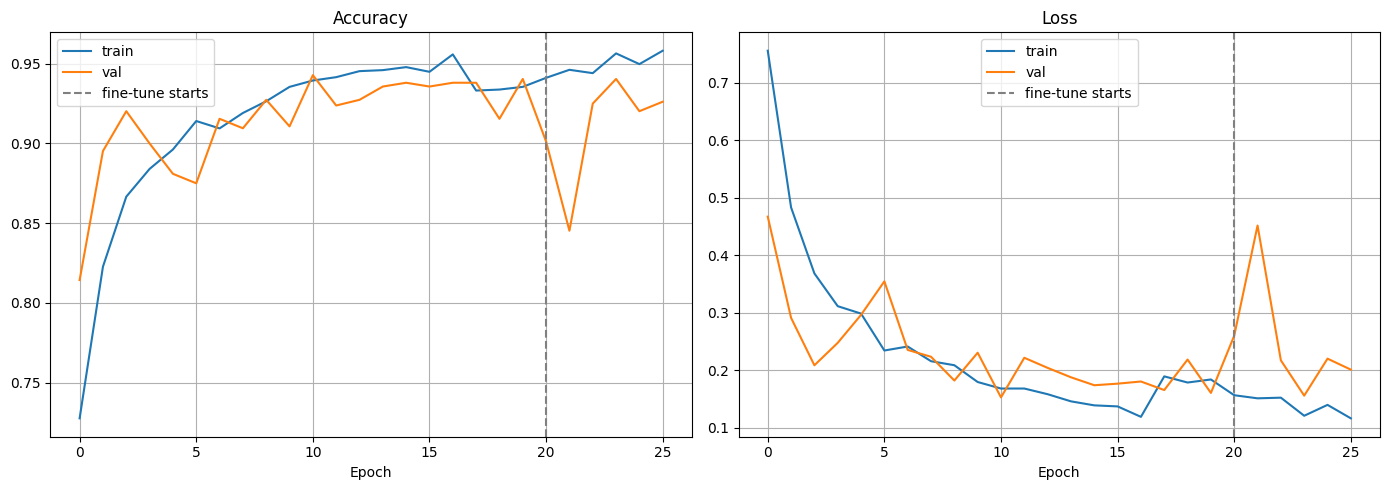

In [14]:
def combine_histories(h1, h2):
    combined = {}
    for key in h1.history:
        combined[key] = h1.history[key] + h2.history.get(key, [])
    return combined

history = combine_histories(history1, history2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['accuracy'], label='train')
axes[0].plot(history['val_accuracy'], label='val')
axes[0].axvline(
    PHASE1_EPOCHS,
    color='gray',
    linestyle='--',
    label='fine-tune starts'
)
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history['loss'], label='train')
axes[1].plot(history['val_loss'], label='val')
axes[1].axvline(
    PHASE1_EPOCHS,
    color='gray',
    linestyle='--',
    label='fine-tune starts'
)
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 11. Evaluation on the Held-Out Test Set

In [15]:
test_label_ids = np.array([CLASS_TO_IDX[l] for l in test_labels])

test_probs = hybrid_model.predict(
    test_ds,
    verbose=1
)

test_pred_ids = np.argmax(test_probs, axis=1)

print("HYBRID MODEL — CLASSIFICATION REPORT")

print(
    classification_report(
        test_label_ids,
        test_pred_ids,
        target_names=CLASS_NAMES
    )
)

100/100 ━━━━━━━━━━━━━━━━━━━━ 60s 328ms/step
HYBRID MODEL — CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma       0.90      0.82      0.85       400
  meningioma       0.84      0.88      0.86       400
     notumor       0.98      0.98      0.98       400
   pituitary       0.96      0.98      0.97       400

    accuracy                           0.92      1600
   macro avg       0.92      0.92      0.92      1600
weighted avg       0.92      0.92      0.92      1600



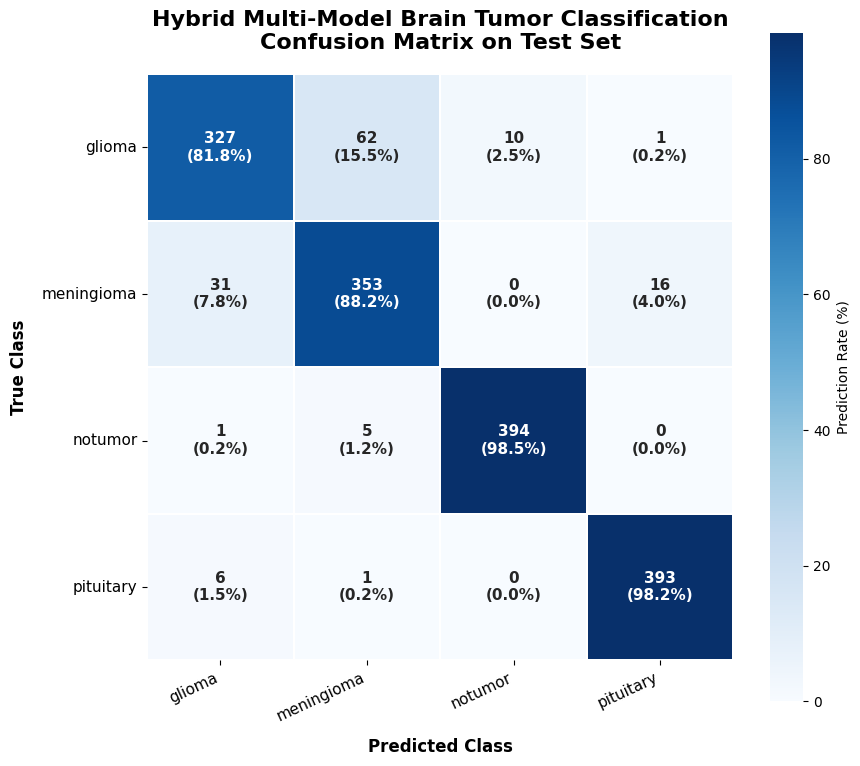

CLASS-WISE CONFUSION MATRIX SUMMARY
glioma          :  327/ 400 correct ( 81.75%)
meningioma      :  353/ 400 correct ( 88.25%)
notumor         :  394/ 400 correct ( 98.50%)
pituitary       :  393/ 400 correct ( 98.25%)


In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Confusion matrix
cm = confusion_matrix(
    test_label_ids,
    test_pred_ids
)

# Row-wise percentages
cm_percent = cm.astype(np.float64) / cm.sum(axis=1, keepdims=True) * 100

# Combined annotations: Count + Percentage
annotations = np.empty_like(cm, dtype=object)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        annotations[i, j] = f"{cm[i, j]}\n({cm_percent[i, j]:.1f}%)"

# Figure
plt.figure(figsize=(9, 8))

ax = sns.heatmap(
    cm_percent,
    annot=annotations,
    fmt="",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    linewidths=1.2,
    linecolor="white",
    square=True,
    cbar_kws={
        "label": "Prediction Rate (%)"
    },
    annot_kws={
        "fontsize": 11,
        "fontweight": "bold"
    }
)

# Titles and labels
plt.title(
    "Hybrid Multi-Model Brain Tumor Classification\n"
    "Confusion Matrix on Test Set",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xlabel(
    "Predicted Class",
    fontsize=12,
    fontweight="bold",
    labelpad=10
)

plt.ylabel(
    "True Class",
    fontsize=12,
    fontweight="bold",
    labelpad=10
)

plt.xticks(
    rotation=25,
    ha="right",
    fontsize=11
)

plt.yticks(
    rotation=0,
    fontsize=11
)

plt.tight_layout()
plt.show()

print("CLASS-WISE CONFUSION MATRIX SUMMARY")

for i, class_name in enumerate(CLASS_NAMES):

    correct = cm[i, i]
    total = cm[i].sum()
    accuracy = (correct / total) * 100 if total > 0 else 0

    print(
        f"{class_name:15s} : "
        f"{correct:4d}/{total:4d} correct "
        f"({accuracy:6.2f}%)"
    )

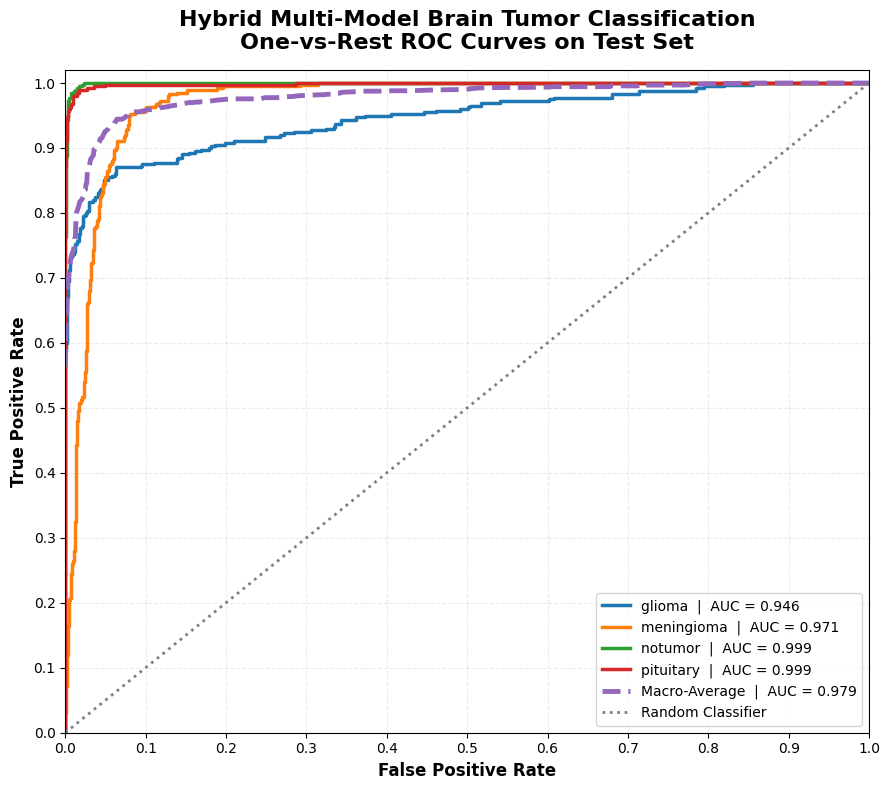

ROC-AUC SUMMARY
glioma          : AUC = 0.9456
meningioma      : AUC = 0.9712
notumor         : AUC = 0.9994
pituitary       : AUC = 0.9985
------------------------------------------------------------
Macro-Average   : AUC = 0.9790


In [17]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

test_bin = label_binarize(
    test_label_ids,
    classes=np.arange(NUM_CLASSES)
)

fpr = {}
tpr = {}
roc_auc = {}

for i, class_name in enumerate(CLASS_NAMES):

    fpr[i], tpr[i], _ = roc_curve(
        test_bin[:, i],
        test_probs[:, i]
    )

    roc_auc[i] = auc(
        fpr[i],
        tpr[i]
    )

all_fpr = np.unique(
    np.concatenate(
        [fpr[i] for i in range(NUM_CLASSES)]
    )
)

mean_tpr = np.zeros_like(all_fpr)

for i in range(NUM_CLASSES):
    mean_tpr += np.interp(
        all_fpr,
        fpr[i],
        tpr[i]
    )

mean_tpr /= NUM_CLASSES

macro_auc = auc(
    all_fpr,
    mean_tpr
)

plt.figure(figsize=(9, 8))

for i, class_name in enumerate(CLASS_NAMES):
    plt.plot(
        fpr[i],
        tpr[i],
        linewidth=2.5,
        label=f"{class_name}  |  AUC = {roc_auc[i]:.3f}"
    )

# Macro average
plt.plot(
    all_fpr,
    mean_tpr,
    linewidth=3.5,
    linestyle="--",
    label=f"Macro-Average  |  AUC = {macro_auc:.3f}"
)

# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle=":",
    linewidth=2,
    color="gray",
    label="Random Classifier"
)

plt.title(
    "Hybrid Multi-Model Brain Tumor Classification\n"
    "One-vs-Rest ROC Curves on Test Set",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "False Positive Rate",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "True Positive Rate",
    fontsize=12,
    fontweight="bold"
)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.xticks(
    np.arange(0, 1.1, 0.1)
)

plt.yticks(
    np.arange(0, 1.1, 0.1)
)

plt.grid(
    True,
    linestyle="--",
    alpha=0.25
)

plt.legend(
    loc="lower right",
    fontsize=10,
    frameon=True
)

plt.tight_layout()
plt.show()

print("ROC-AUC SUMMARY")

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:15s} : AUC = {roc_auc[i]:.4f}"
    )

print("-" * 60)
print(
    f"{'Macro-Average':15s} : AUC = {macro_auc:.4f}"
)

## 12. Individual Backbone Baselines

To show what the fusion actually buys us, each backbone is also trained **on its own** as a
lightweight standalone classifier (frozen backbone + small head, quick training). These same
trained models are reused in Section 13 as the base learners of a soft-voting ensemble — an
alternative to the fused model that is far cheaper to train if you don't have a big GPU.

In [18]:
from tensorflow.keras import callbacks

In [19]:
import os
import tensorflow as tf

BASELINE_EPOCHS = 15

# PRETRAINED STANDALONE MODEL
def build_standalone_pretrained(
    name,
    Backbone,
    preprocess_fn,
    num_classes=NUM_CLASSES
):

    inp = layers.Input(
        shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
        name=f"{name}_input"
    )

    # Preprocessing
    x = layers.Lambda(
        lambda z: preprocess_fn(z),
        name=f"{name}_preprocess"
    )(inp)

    # Load ImageNet pretrained backbone
    if name == "efficientnetb3":

        try:
            # First try normal Keras ImageNet weights
            base = Backbone(
                include_top=False,
                weights="imagenet",
                input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
                pooling="avg",
                name=f"{name}_backbone"
            )

        except Exception as e:

            print(
                "\nEfficientNetB3 standard ImageNet download failed."
            )
            print("Using legacy EfficientNetB3 weights instead.")

            # Legacy weight location
            legacy_weight_url = (
                "https://storage.googleapis.com/"
                "keras-applications/efficientnetb3_notop.h5"
            )

            # Local cache path
            legacy_weight_path = os.path.expanduser(
                "~/.keras/models/efficientnetb3_notop.h5"
            )

            # Download only if not already available
            if not os.path.exists(legacy_weight_path):

                legacy_weight_path = tf.keras.utils.get_file(
                    fname="efficientnetb3_notop.h5",
                    origin=legacy_weight_url,
                    cache_subdir="models"
                )

            # Build architecture without automatic weights
            base = Backbone(
                include_top=False,
                weights=None,
                input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
                pooling="avg",
                name=f"{name}_backbone"
            )

            # Load legacy ImageNet weights manually
            base.load_weights(
                legacy_weight_path
            )

    else:

        base = Backbone(
            include_top=False,
            weights="imagenet",
            input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
            pooling="avg",
            name=f"{name}_backbone"
        )

    # Freeze backbone
    base.trainable = False

    # Raw GAP feature
    gap = base(x)

    # Classification head
    x = layers.Dense(
        128,
        activation="relu",
        name=f"{name}_dense"
    )(gap)

    x = layers.Dropout(
        0.30,
        name=f"{name}_dropout"
    )(x)

    out = layers.Dense(
        num_classes,
        activation="softmax",
        dtype="float32",
        name=f"{name}_output"
    )(x)

    model = models.Model(
        inputs=inp,
        outputs=out,
        name=f"{name}_standalone"
    )

    model.compile(
        optimizer=optimizers.Adam(
            learning_rate=1e-4
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

# CUSTOM / MEDICALNET STANDALONE MODEL
def build_standalone_custom(
    name,
    feature_fn,
    num_classes=NUM_CLASSES
):

    inp = layers.Input(
        shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
        name=f"{name}_input"
    )

    gap = feature_fn(inp)

    x = layers.Dense(
        128,
        activation="relu",
        name=f"{name}_dense"
    )(gap)

    x = layers.Dropout(
        0.30,
        name=f"{name}_dropout"
    )(x)

    out = layers.Dense(
        num_classes,
        activation="softmax",
        dtype="float32",
        name=f"{name}_output"
    )(x)

    model = models.Model(
        inputs=inp,
        outputs=out,
        name=f"{name}_standalone"
    )

    model.compile(
        optimizer=optimizers.Adam(
            learning_rate=1e-4
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

# BASELINE STORAGE
baseline_models = {}
baseline_histories = {}

# FUNCTION TO CREATE A FRESH CALLBACK
# IMPORTANT: NEW CALLBACK FOR EVERY MODEL
def get_baseline_callbacks():

    return [
        callbacks.EarlyStopping(
            monitor="val_accuracy",
            mode="max",
            patience=3,
            restore_best_weights=True,
            verbose=1
        )
    ]

# PRETRAINED BASELINES
standalone_specs = {

    "vgg16": (
        vgg16.VGG16,
        vgg16.preprocess_input
    ),

    "resnet50": (
        resnet50.ResNet50,
        resnet50.preprocess_input
    ),

    "densenet121": (
        densenet.DenseNet121,
        densenet.preprocess_input
    ),

    "efficientnetb3": (
        efficientnet.EfficientNetB3,
        efficientnet.preprocess_input
    ),
}


for name, (Backbone, preprocess_fn) in standalone_specs.items():

    print(f"Training standalone {name}")
    
    # Build model
    m = build_standalone_pretrained(
        name=name,
        Backbone=Backbone,
        preprocess_fn=preprocess_fn,
        num_classes=NUM_CLASSES
    )

    # Fresh EarlyStopping object for this model
    model_callbacks = get_baseline_callbacks()

    # Train
    h = m.fit(
        train_ds,
        validation_data=val_ds,
        epochs=BASELINE_EPOCHS,
        class_weight=class_weights,
        callbacks=model_callbacks,
        verbose=1
    )

    baseline_models[name] = m
    baseline_histories[name] = h

# CUSTOM CNN
def _custom_cnn_feature(inp):

    return build_custom_cnn_branch(
        inp,
        proj_dim=PROJ_DIM
    )


print("Training standalone custom CNN")

m = build_standalone_custom(
    name="customcnn",
    feature_fn=_custom_cnn_feature,
    num_classes=NUM_CLASSES
)

h = m.fit(
    train_ds,
    validation_data=val_ds,
    epochs=BASELINE_EPOCHS,
    class_weight=class_weights,
    callbacks=get_baseline_callbacks(),
    verbose=1
)

baseline_models["customcnn"] = m
baseline_histories["customcnn"] = h

# MEDICALNET-INSPIRED
def _mednet_feature(inp):

    return build_medicalnet_inspired_branch(
        inp,
        proj_dim=PROJ_DIM
    )


print("Training standalone MedicalNet-inspired")

m = build_standalone_custom(
    name="mednet_inspired",
    feature_fn=_mednet_feature,
    num_classes=NUM_CLASSES
)

h = m.fit(
    train_ds,
    validation_data=val_ds,
    epochs=BASELINE_EPOCHS,
    class_weight=class_weights,
    callbacks=get_baseline_callbacks(),
    verbose=1
)

baseline_models["mednet_inspired"] = m
baseline_histories["mednet_inspired"] = h

Training standalone vgg16
Epoch 1/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 59s 188ms/step - accuracy: 0.5477 - loss: 1.6786 - val_accuracy: 0.7893 - val_loss: 0.6056
Epoch 2/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 54s 180ms/step - accuracy: 0.7468 - loss: 0.7046 - val_accuracy: 0.8393 - val_loss: 0.4515
Epoch 3/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 82s 181ms/step - accuracy: 0.7908 - loss: 0.5762 - val_accuracy: 0.8512 - val_loss: 0.4055
Epoch 4/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 54s 180ms/step - accuracy: 0.8164 - loss: 0.4951 - val_accuracy: 0.8690 - val_loss: 0.3747
Epoch 5/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 54s 180ms/step - accuracy: 0.8334 - loss: 0.4395 - val_accuracy: 0.8690 - val_loss: 0.3621
Epoch 6/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 54s 180ms/step - accuracy: 0.8536 - loss: 0.3990 - val_accuracy: 0.8786 - val_loss: 0.3422
Epoch 7/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 54s 180ms/step - accuracy: 0.8599 - loss: 0.3810 - val_accuracy: 0.8786 - val_loss: 0.3387
Epoch 8/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 54s 179ms/step - 

100/100 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step
vgg16              test accuracy: 0.8325
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 50ms/step
resnet50           test accuracy: 0.8469
100/100 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step
densenet121        test accuracy: 0.8275
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step
efficientnetb3     test accuracy: 0.7994
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step
customcnn          test accuracy: 0.6900
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step
mednet_inspired    test accuracy: 0.8450


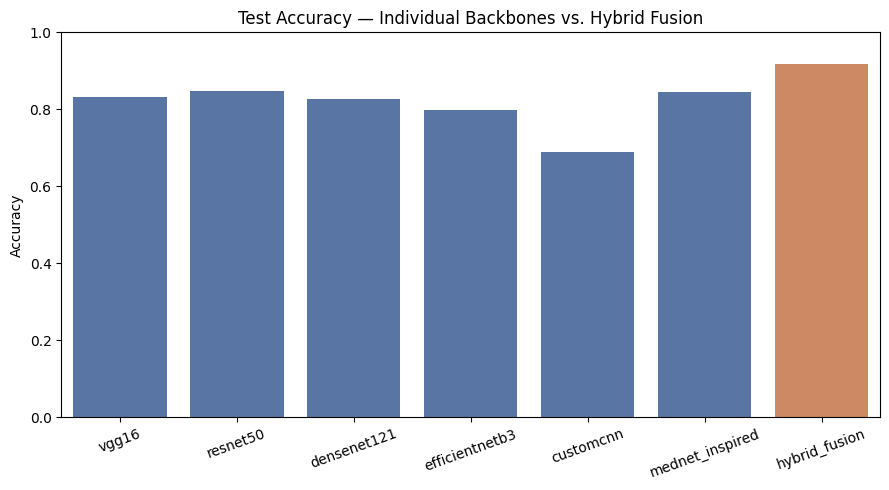

In [20]:
baseline_test_probs = {}
baseline_test_acc = {}

for name, m in baseline_models.items():
    probs = m.predict(test_ds)
    preds = np.argmax(probs, axis=1)
    acc = (preds == test_label_ids).mean()
    baseline_test_probs[name] = probs
    baseline_test_acc[name] = acc
    print(f"{name:18s} test accuracy: {acc:.4f}")

hybrid_test_acc = (test_pred_ids == test_label_ids).mean()
baseline_test_acc['hybrid_fusion'] = hybrid_test_acc

plt.figure(figsize=(9, 5))
names = list(baseline_test_acc.keys())
accs = [baseline_test_acc[n] for n in names]
colors = ['#4C72B0'] * (len(names) - 1) + ['#DD8452']
sns.barplot(x=names, y=accs, hue=names, palette=colors, legend=False)
plt.title('Test Accuracy — Individual Backbones vs. Hybrid Fusion')
plt.ylabel('Accuracy')
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


## 13. Weighted Soft-Voting Ensemble (Approach B)

If training the full fused model end-to-end isn't feasible on your hardware, this section builds
an ensemble the cheap way: reuse the **already-trained standalone models** from Section 12 and
combine their predicted probabilities with weights proportional to each model's validation
accuracy. No retraining, no giant multi-branch graph in memory at once.

In [21]:
val_label_ids = np.array([CLASS_TO_IDX[l] for l in val_labels])

val_accs = {}
for name, m in baseline_models.items():
    val_probs = m.predict(val_ds)
    val_preds = np.argmax(val_probs, axis=1)
    val_accs[name] = (val_preds == val_label_ids).mean()

# Softmax-normalize validation accuracies into ensemble weights
weight_arr = np.array(list(val_accs.values()))
ensemble_weights = weight_arr / weight_arr.sum()
ensemble_weights = dict(zip(val_accs.keys(), ensemble_weights))
print("Ensemble weights (by validation accuracy):")
for k, v in ensemble_weights.items():
    print(f"  {k:18s} {v:.4f}")

def weighted_soft_vote(probs_dict, weights_dict):
    total = None
    for name, probs in probs_dict.items():
        w = weights_dict[name]
        total = w * probs if total is None else total + w * probs
    return total

ensemble_test_probs = weighted_soft_vote(baseline_test_probs, ensemble_weights)
ensemble_preds = np.argmax(ensemble_test_probs, axis=1)
ensemble_acc = (ensemble_preds == test_label_ids).mean()

print(f"\nWeighted soft-voting ensemble test accuracy: {ensemble_acc:.4f}")
print(f"Hybrid fusion model test accuracy:            {hybrid_test_acc:.4f}")
print("\nEnsemble classification report:")
print(classification_report(test_label_ids, ensemble_preds, target_names=CLASS_NAMES))


53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 119ms/step
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 115ms/step
53/53 ━━━━━━━━━━━━━━━━━━━━ 13s 251ms/step
53/53 ━━━━━━━━━━━━━━━━━━━━ 11s 209ms/step
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step
53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step
Ensemble weights (by validation accuracy):
  vgg16              0.1730
  resnet50           0.1730
  densenet121        0.1666
  efficientnetb3     0.1666
  customcnn          0.1480
  mednet_inspired    0.1728

Weighted soft-voting ensemble test accuracy: 0.8588
Hybrid fusion model test accuracy:            0.9169

Ensemble classification report:
              precision    recall  f1-score   support

      glioma       0.96      0.69      0.80       400
  meningioma       0.82      0.76      0.79       400
     notumor       0.83      0.99      0.90       400
   pituitary       0.86      0.99      0.92       400

    accuracy                           0.86      1600
   macro avg       0.87      0.86      0.85      1600
weighted avg       0.87 

## 14. Grad-CAM Explainability

For a medical-imaging model, showing *which pixels* drove a prediction matters. This uses
Grad-CAM on the DenseNet121 branch inside the hybrid model to highlight the regions that most
influenced the final classification.

Backbone found: densenet121
Last Conv layer: conv5_block16_2_conv


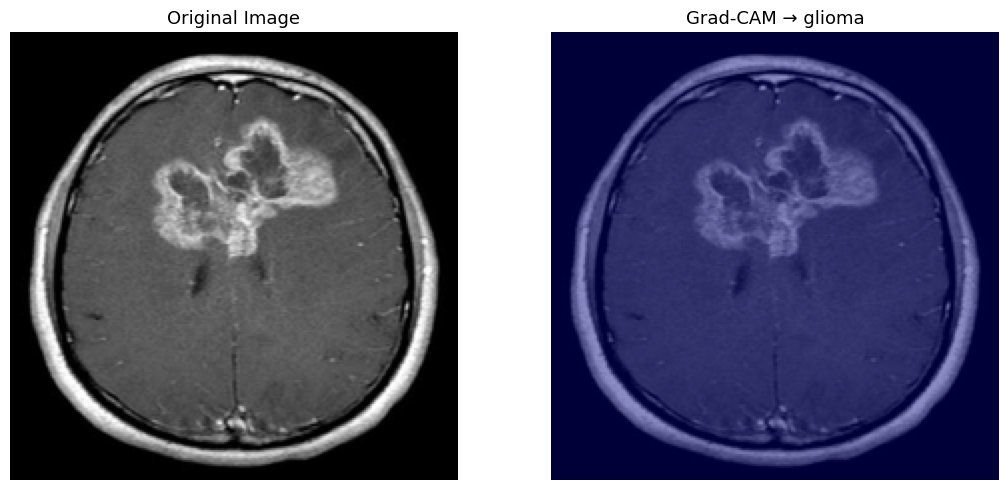

In [22]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

densenet_branch = hybrid_model.get_layer('densenet121_branch')

densenet_backbone = None
for layer in densenet_branch.layers:
    if isinstance(layer, tf.keras.Model) and 'densenet' in layer.name.lower():
        densenet_backbone = layer
        break

if densenet_backbone is None:
    # fallback
    densenet_backbone = densenet_branch.layers[1]  # সাধারণত দ্বিতীয় লেয়ার হয়

print("Backbone found:", densenet_backbone.name)

last_conv_layer = None
for layer in reversed(densenet_backbone.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer = layer
        break

print("Last Conv layer:", last_conv_layer.name)


def make_gradcam_heatmap(img_array, pred_index=None):
    grad_model = tf.keras.models.Model(
        inputs=densenet_backbone.input,
        outputs=[last_conv_layer.output, densenet_backbone.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        
        if pred_index is None:
            hybrid_pred = hybrid_model(img_array)
            pred_index = tf.argmax(hybrid_pred[0])
        
        class_channel = predictions[:, pred_index] if predictions.shape[-1] > 1 else predictions

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    
    return heatmap.numpy(), int(pred_index)


def show_gradcam(img_path, alpha=0.45):
    img = Image.open(img_path).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
    img_array = np.expand_dims(np.array(img).astype(np.float32), axis=0)

    # DenseNet preprocessing  (caffe style)
    img_array_preprocessed = tf.keras.applications.densenet.preprocess_input(img_array.copy())

    heatmap, pred_index = make_gradcam_heatmap(img_array_preprocessed)

    # Create Heatmap
    heatmap_resized = np.array(
        Image.fromarray(np.uint8(255 * heatmap)).resize((IMAGE_SIZE, IMAGE_SIZE))
    )
    heatmap_colored = plt.cm.jet(heatmap_resized / 255.0)[..., :3]

    overlay = (1 - alpha) * (np.array(img) / 255.0) + alpha * heatmap_colored
    overlay = np.clip(overlay, 0, 1)

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    
    axes[0].imshow(img)
    axes[0].set_title("Original Image", fontsize=13)
    axes[0].axis('off')

    axes[1].imshow(overlay)
    axes[1].set_title(f"Grad-CAM → {CLASS_NAMES[pred_index]}", fontsize=13)
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

# Example
show_gradcam(test_paths[0])

## 15. Save / Load the Hybrid Model

In [23]:
hybrid_model.save_weights('hybrid_brain_tumor_weights.weights.h5')

hybrid_model.save('hybrid_brain_tumor_model.keras')

In [24]:
hybrid_model, backbones = build_hybrid_model()

hybrid_model.load_weights('hybrid_brain_tumor_weights.weights.h5')

print("Model loaded successfully!")

Model loaded successfully!


## 16. Single-Image Inference Tool

In [25]:
def detect_and_display(img_path, model=hybrid_model, image_size=IMAGE_SIZE, class_names=CLASS_NAMES):
    """Loads an MRI image, runs the hybrid model, and displays the predicted class + confidence."""
    try:
        img = Image.open(img_path).convert('RGB').resize((image_size, image_size))
        img_array = np.expand_dims(np.array(img).astype(np.float32), axis=0)  # kept in [0,255]

        predictions = model.predict(img_array, verbose=0)
        predicted_index = int(np.argmax(predictions, axis=1)[0])
        confidence = float(np.max(predictions, axis=1)[0])

        predicted_class = class_names[predicted_index]
        result = "No Tumor" if predicted_class == 'notumor' else f"Tumor: {predicted_class}"

        plt.imshow(img)
        plt.axis('off')
        plt.title(f"{result}  (confidence: {confidence * 100:.2f}%)")
        plt.show()

        return predicted_class, confidence

    except Exception as e:
        print("Error processing the image:", str(e))
        return None, None


## 17. Batch Inference Demo

2026-10-24 15:10:23.241869: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:10:23.376075: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:10:23.679653: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:10:23.821458: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:10:23.962515: E external/local_xla/xla/stream_

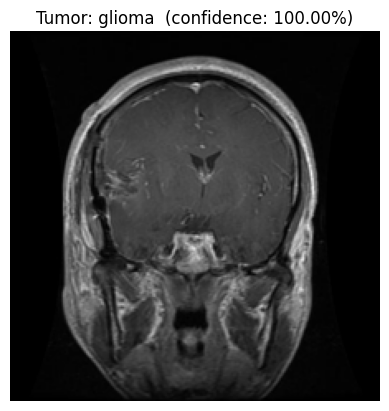

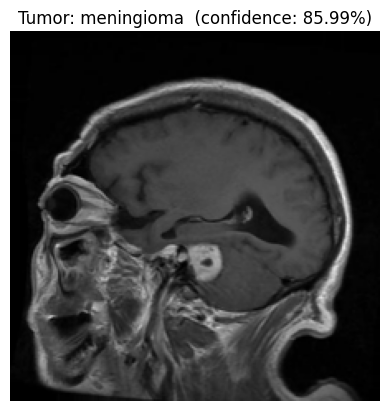

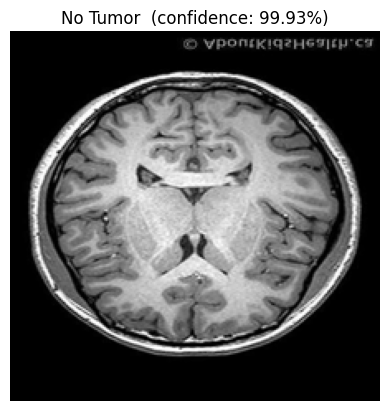

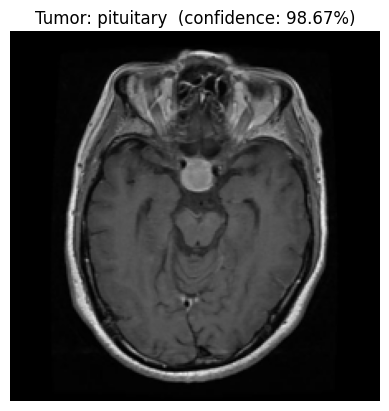

In [26]:
example_images = [
    "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/glioma/Te-gl_112.jpg",
    "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/meningioma/Te-aug-me_101.jpg",
    "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/notumor/Te-no_109.jpg",
    "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/pituitary/Te-pi_119.jpg",
]

for path in example_images:
    if os.path.exists(path):
        detect_and_display(path)
    else:
        print(f"Skipping (not found): {path}")


## 18. Appendix — Plugging In a *True* 3D MedicalNet Branch

If you later have **3D volumetric scans** (NIfTI/DICOM series, not single 2D slices) and want the
real Med3D-pretrained 3D ResNet instead of the 2D residual stand-in used above:

1. Get the official Med3D repository and its PyTorch `.pth` checkpoints (e.g. `resnet_18_23dataset.pth`).
2. Build the 3D ResNet in PyTorch and load those weights; run it as a **separate PyTorch inference service**
   (TensorFlow cannot load PyTorch `.pth` weights directly, and Med3D's architecture is 3D-convolutional).
3. For each volume, extract the Med3D penultimate-layer embedding (a feature vector) with that PyTorch model.
4. Feed those embeddings into this notebook as an **extra precomputed input** — e.g. save them as a NumPy
   array keyed by patient/scan ID, load them alongside the 2D slice paths, and concatenate them with the
   other five branches' projected features before the fusion `Dense` layers (same pattern as
   `build_projection_head`, just applied to a NumPy vector `Input` instead of an image branch).
5. Train the fusion head as in Section 9, now with a genuine 3D-pretrained medical signal included.

This keeps the same hybrid-fusion design used throughout the notebook, and is the technically correct way
to bring real MedicalNet weights into the ensemble once 3D data is available.

In [27]:
!pip install tensorflow scikit-learn matplotlib seaborn pillow

In [28]:
import os
import glob
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
from tensorflow.keras.applications import vgg16, resnet50, densenet, efficientnet

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
)
from sklearn.preprocessing import label_binarize

print("TensorFlow version:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("GPUs detected:", gpus)
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

TensorFlow version: 2.20.0
GPUs detected: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


# Brain Tumor MRI — Closing the Real-World Gaps

Companion to `brain-tumor-hybrid-model.ipynb`. **Run it after that notebook, in the same session** (it reuses `hybrid_model`, `baseline_models`, `test_probs`, the path/label lists, etc.).

## Honest scope

Some of the nine gaps are *engineering* problems this notebook can attack. Others need **data, hospitals, or regulators**, and no code can substitute for those. The table says which is which.

| # | Gap | What this notebook actually does | What code alone cannot do |
|---|-----|----------------------------------|---------------------------|
| 1 | Generalization / domain shift | Leakage audit, pseudo-domain leave-one-domain-out test, shortcut probe, corruption stress test, robust fine-tuning | Real multi-centre validation needs scans from other hospitals |
| 2 | 2D slice vs 3D / patient level | Patient-level aggregation, patient-grouped splits, attention-MIL over slices, 3D CNN scaffold | This Kaggle set has **no patient IDs and no volumes** — you need BraTS / UCSF-PDGM / your own PACS export |
| 3 | Multi-modal | 4-sequence (T1, T1ce, T2, FLAIR) 3D model with modality dropout + missing-sequence test | Needs multi-sequence data |
| 4 | Trust / validation | Calibration, ensemble uncertainty, selective prediction, conformal sets, **fixed** Grad-CAM + faithfulness test, shadow-mode logger | A prospective study is a clinical study, not a notebook |
| 5 | Rare / atypical cases | Epistemic-uncertainty and conformal-set-size deferral | Nothing can be learned for classes with no data |
| 6 | Workflow | DICOM reader, sensitivity-first triage policy, structured output | PACS/RIS integration is work with hospital IT |
| 7 | Compute / deployment | Distillation to EfficientNet-B0, TFLite export, latency table | — |
| 8 | Data quality | Duplicate / leakage audit, noise and artifact robustness | Multi-reader relabelling |
| 9 | Regulatory / ethics | Model card, subgroup-audit tooling, checklist | Approval itself and legal liability |

**Bugs found in the original notebook:** (a) the Grad-CAM cell takes `predictions[:, pred_index]` from DenseNet's *pooled 1024-d feature vector* (not a class score) and double-preprocesses the image, so its heatmaps are not meaningful — fixed in §4; (b) the Kaggle set contains near-duplicate / augmented images, so train/val/test leakage is likely — measured in §1.

> This is research code. It is **not** a medical device and must not be used for clinical decisions.

In [29]:
import os, io, json, math, time, hashlib, sqlite3, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import stats
from scipy.optimize import minimize_scalar
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score
warnings.filterwarnings("ignore")

OUT_DIR = "gap_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

_REQUIRED = [
    "hybrid_model", "baseline_models", "baseline_test_probs", "train_paths", "train_labels",
    "val_paths", "val_labels", "test_paths", "test_labels", "CLASS_NAMES", "CLASS_TO_IDX",
    "NUM_CLASSES", "IMAGE_SIZE", "BATCH_SIZE", "SEED", "make_dataset", "_load_image",
    "data_augmentation", "class_weights", "test_probs",
]
_missing = [n for n in _REQUIRED if n not in globals()]
if _missing:
    raise RuntimeError(
        "Run brain-tumor-hybrid-model.ipynb first (same session). Missing: " + ", ".join(_missing)
    )

NOTUMOR = CLASS_TO_IDX["notumor"]
train_ids = np.array([CLASS_TO_IDX[l] for l in train_labels])
val_label_ids = np.array([CLASS_TO_IDX[l] for l in val_labels])
test_label_ids = np.array([CLASS_TO_IDX[l] for l in test_labels])
print("Ready. Classes:", CLASS_NAMES, "| notumor index:", NOTUMOR)

Ready. Classes: ['glioma', 'meningioma', 'notumor', 'pituitary'] | notumor index: 2


In [30]:
# ---------- generic metric helpers (pure numpy / scipy / sklearn) ----------
def softmax_np(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

def macro_f1(y, pred):
    return f1_score(y, pred, average="macro", labels=np.arange(NUM_CLASSES), zero_division=0)

def tumor_miss_rate(y, pred, notumor_idx=None):
    """Among truly-tumor cases, fraction predicted as 'notumor' (the dangerous error)."""
    notumor_idx = NOTUMOR if notumor_idx is None else notumor_idx
    t = np.asarray(y) != notumor_idx
    return float((np.asarray(pred)[t] == notumor_idx).mean()) if t.any() else float("nan")

def clopper_pearson(k, n, alpha=0.05):
    """Exact two-sided binomial CI."""
    if n == 0:
        return 0.0, 1.0
    lo = 0.0 if k == 0 else stats.beta.ppf(alpha / 2, k, n - k + 1)
    hi = 1.0 if k == n else stats.beta.ppf(1 - alpha / 2, k + 1, n - k)
    return float(lo), float(hi)

def clopper_pearson_lower(k, n, alpha=0.05):
    """Exact one-sided lower confidence bound."""
    if n == 0 or k == 0:
        return 0.0
    return float(stats.beta.ppf(alpha, k, n - k + 1))

def predict_probs(model, paths, labels):
    """Ordered (non-shuffled) predictions for a path list."""
    return model.predict(make_dataset(paths, labels, training=False), verbose=0)

---
## 19. Data integrity audit (Gap 8, and the foundation for Gap 1)

Before measuring *generalization* we must check the test set is not secretly part of the training set. The audit uses an exact file hash plus a 64-bit perceptual hash (dHash), also computed on the horizontally flipped image, because the Kaggle set contains flipped/augmented copies.

In [31]:
_LUT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def popcount64(x):
    x = np.ascontiguousarray(x, dtype=np.uint64)
    if hasattr(np, "bitwise_count"):
        return np.bitwise_count(x)
    b = x.view(np.uint8).reshape(*x.shape, 8)
    return _LUT[b].sum(-1)

def _dhash(gray_u8):
    small = np.asarray(Image.fromarray(gray_u8).resize((9, 8), Image.BILINEAR), dtype=np.float32)
    bits = (small[:, 1:] > small[:, :-1]).ravel()          # 64 bits
    return np.packbits(bits).view(np.uint64)[0]

def image_meta_and_hash(path):
    with open(path, "rb") as f:
        md5 = hashlib.md5(f.read()).hexdigest()
    with Image.open(path) as im:
        w, h = im.size
        g = np.asarray(im.convert("L"), dtype=np.uint8)
    gf = g.astype(np.float32)
    p99 = float(np.percentile(gf, 99))
    return dict(path=path, width=w, height=h, aspect=w / h, mean=float(gf.mean()),
                std=float(gf.std()), p99=p99, bg_frac=float((gf < 10).mean()), md5=md5,
                h=_dhash(g), hf=_dhash(np.ascontiguousarray(g[:, ::-1])))

def build_meta(paths, labels, split):
    it = paths
    try:
        from tqdm.auto import tqdm
        it = tqdm(paths, desc=split)
    except Exception:
        pass
    df = pd.DataFrame([image_meta_and_hash(p) for p in it])
    df["label"] = list(labels)
    df["split"] = split
    return df

def nearest_hamming(q, qf, ref, chunk=128):
    """Min Hamming distance (over original + flipped query) to any reference hash."""
    q, qf, ref = (np.asarray(a, dtype=np.uint64) for a in (q, qf, ref))
    best = np.full(len(q), 64, dtype=np.int16)
    arg = np.zeros(len(q), dtype=np.int64)
    for s in range(0, len(q), chunk):
        a = q[s:s + chunk, None] ^ ref[None, :]
        b = qf[s:s + chunk, None] ^ ref[None, :]
        d = np.minimum(popcount64(a), popcount64(b))
        j = d.argmin(1)
        best[s:s + chunk] = d[np.arange(len(j)), j]
        arg[s:s + chunk] = j
    return best, arg

def leakage_flags(q_df, ref_df, thr=4):
    d, _ = nearest_hamming(q_df["h"].to_numpy(np.uint64), q_df["hf"].to_numpy(np.uint64),
                           ref_df["h"].to_numpy(np.uint64))
    exact = q_df["md5"].isin(set(ref_df["md5"])).to_numpy()
    return (d <= thr) | exact, d

In [32]:
meta_train = build_meta(train_paths, train_labels, "train")
meta_val   = build_meta(val_paths,   val_labels,   "val")
meta_test  = build_meta(test_paths,  test_labels,  "test")
meta_all = pd.concat([meta_train, meta_val, meta_test], ignore_index=True)

THR = 4   # Hamming distance <= THR (of 64 bits) counts as near-duplicate
val_leak,  d_val  = leakage_flags(meta_val,  meta_train, THR)
test_leak, d_test = leakage_flags(meta_test, pd.concat([meta_train, meta_val]), THR)
print(f"val  images that duplicate a TRAIN image : {val_leak.sum():5d} / {len(val_leak)}  ({val_leak.mean():.1%})")
print(f"test images that duplicate TRAIN/VAL     : {test_leak.sum():5d} / {len(test_leak)}  ({test_leak.mean():.1%})")

test_pred = np.argmax(test_probs, axis=1)     # `test_probs` = the original notebook's hybrid predictions (before robust fine-tuning)
clean = ~test_leak
print(f"\nTest accuracy, full set            : {(test_pred == test_label_ids).mean():.4f}  (n={len(test_pred)})")
print(f"Test accuracy, leakage-free subset : {(test_pred[clean] == test_label_ids[clean]).mean():.4f}  (n={clean.sum()})")
print(f"Tumor-miss rate, leakage-free      : {tumor_miss_rate(test_label_ids[clean], test_pred[clean]):.4f}")
print("\nIf the leakage-free numbers are noticeably lower, report THOSE.")

train:   0%|          | 0/4760 [00:00<?, ?it/s]

val:   0%|          | 0/840 [00:00<?, ?it/s]

test:   0%|          | 0/1600 [00:00<?, ?it/s]

val  images that duplicate a TRAIN image :   699 / 840  (83.2%)
test images that duplicate TRAIN/VAL     :  1390 / 1600  (86.9%)

Test accuracy, full set            : 0.9169  (n=1600)
Test accuracy, leakage-free subset : 0.7333  (n=210)
Tumor-miss rate, leakage-free      : 0.0287

If the leakage-free numbers are noticeably lower, report THOSE.


---
## 20. Domain shift / multi-centre generalization (Gap 1)

**What is and isn't possible here.** The Kaggle set merges several public sources and gives no scanner or site labels, so *true* multi-centre testing is impossible. What we can do:

1. Build **pseudo-domains** by clustering acquisition properties (image size, aspect, intensity statistics). These are *proxies* for site/protocol, not ground truth.
2. Check for **shortcut learning**: if image geometry alone predicts the tumor class, a network can cheat.
3. Run **leave-one-domain-out (LODO)** evaluation: train on all pseudo-domains but one, test on the held-out one. The drop versus an in-domain split estimates the generalization gap.
4. **Stress-test** the real hybrid model with synthetic scanner-like corruptions (gamma, bias field, noise, blur, low resolution, contrast).
5. **Fine-tune with domain-randomization augmentation**, then re-run the stress test to see if it helped.

When you get real multi-site data (BraTS has institution info for many cases), pass the real site IDs as `groups` to the same LODO code.

In [33]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict

META_COLS = ["width", "height", "aspect", "mean", "std", "p99", "bg_frac"]
SIZE_COLS = ["width", "height", "aspect"]

def build_pseudo_domains(meta, k=4, seed=42):
    f = np.column_stack([np.log(meta["width"]), np.log(meta["height"]), meta["aspect"],
                         meta["mean"] / 255, meta["std"] / 255, meta["p99"] / 255, meta["bg_frac"]])
    Z = StandardScaler().fit_transform(f)
    return KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(Z)

def cramers_v(ct):
    ct = np.asarray(ct)
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    k = min(ct.shape) - 1
    return float(np.sqrt(chi2 / (ct.sum() * k))) if k > 0 else 0.0

def metadata_shortcut_probe(meta, cols, seed=42):
    """Can acquisition metadata ALONE predict the class? (5-fold CV accuracy vs majority baseline)"""
    X, y = meta[cols].to_numpy(), meta["label"].to_numpy()
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    acc = cross_val_score(HistGradientBoostingClassifier(random_state=seed), X, y, cv=cv).mean()
    return float(acc), float(pd.Series(y).value_counts(normalize=True).max())

def leave_one_group_out(fit_predict, y, groups, min_n=30):
    """fit_predict(train_idx, test_idx) -> probabilities [len(test_idx), NUM_CLASSES]."""
    rows = []
    for g in np.unique(groups):
        te = np.where(groups == g)[0]
        tr = np.where(groups != g)[0]
        if len(te) < min_n:
            continue
        pred = fit_predict(tr, te).argmax(1)
        rows.append(dict(group=g, n=len(te), acc=accuracy_score(y[te], pred),
                         macro_f1=macro_f1(y[te], pred), tumor_miss=tumor_miss_rate(y[te], pred)))
    return pd.DataFrame(rows)

def _make_clf():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, C=0.1))

def lodo_report(features, y, groups, seed=42):
    """LODO accuracy per held-out group vs the same group's accuracy under ordinary 5-fold CV."""
    def fp(tr, te):
        clf = _make_clf().fit(features[tr], y[tr])
        P = np.zeros((len(te), NUM_CLASSES))
        P[:, clf.classes_] = clf.predict_proba(features[te])
        return P
    lodo = leave_one_group_out(fp, y, groups)
    cv_pred = cross_val_predict(_make_clf(), features, y,
                                cv=StratifiedKFold(5, shuffle=True, random_state=seed))
    lodo["in_domain_acc"] = [accuracy_score(y[groups == g], cv_pred[groups == g]) for g in lodo["group"]]
    lodo["generalization_gap"] = lodo["in_domain_acc"] - lodo["acc"]
    return lodo

In [34]:
K_DOMAINS = 4
meta_all["domain"] = build_pseudo_domains(meta_all, k=K_DOMAINS, seed=SEED)

print("Pseudo-domain summary (median image size, intensity):")
print(meta_all.groupby("domain").agg(n=("path", "size"), width=("width", "median"),
      height=("height", "median"), mean_int=("mean", "mean"), bg=("bg_frac", "mean")).round(2))

ct = pd.crosstab(meta_all["domain"], meta_all["label"])
print("\nDomain x class counts:\n", ct)
V = cramers_v(ct)
print(f"\nCramer's V (domain vs class): {V:.2f}   (0 = independent, 1 = domain fully determines class)")

acc_size, chance = metadata_shortcut_probe(meta_all, SIZE_COLS, SEED)
acc_all,  _      = metadata_shortcut_probe(meta_all, META_COLS, SEED)
print(f"\nShortcut probe - majority-class baseline : {chance:.3f}")
print(f"Shortcut probe - image SIZE only         : {acc_size:.3f}")
print(f"Shortcut probe - size + intensity stats  : {acc_all:.3f}")
if acc_size > chance + 0.10:
    print("WARNING: image geometry alone predicts the class far above chance. "
          "The network may exploit acquisition artifacts rather than anatomy. Treat headline accuracy with suspicion.")

Pseudo-domain summary (median image size, intensity):
           n  width  height  mean_int    bg
domain                                     
0       2471  512.0   512.0     52.25  0.28
1       1536  225.0   236.0     68.26  0.30
2       3109  512.0   512.0     33.73  0.53
3         84  420.0   280.0     42.61  0.59

Domain x class counts:
 label   glioma  meningioma  notumor  pituitary
domain                                        
0          277         564      290       1340
1           38         196     1271         31
2         1482        1029      169        429
3            3          11       70          0

Cramer's V (domain vs class): 0.50   (0 = independent, 1 = domain fully determines class)

Shortcut probe - majority-class baseline : 0.250
Shortcut probe - image SIZE only         : 0.516
Shortcut probe - size + intensity stats  : 0.815


In [35]:
import tensorflow as tf
from tensorflow.keras.applications import densenet

_fe = tf.keras.applications.DenseNet121(include_top=False, weights="imagenet", pooling="avg")

def extract_densenet_features(paths, labels):
    ds = make_dataset(paths, labels, training=False).map(
        lambda x, y: (densenet.preprocess_input(x), y))
    return _fe.predict(ds, verbose=0)

all_paths  = meta_all["path"].tolist()
all_labels = meta_all["label"].tolist()
feats_all = extract_densenet_features(all_paths, all_labels)
y_all = np.array([CLASS_TO_IDX[l] for l in all_labels])
print("Feature matrix:", feats_all.shape)

Feature matrix: (7200, 1024)


 group    n    acc  macro_f1  tumor_miss  in_domain_acc  generalization_gap
     0 2471 0.8422    0.8254      0.0138         0.9587              0.1166
     1 1536 0.8555    0.5875      0.1396         0.9551              0.0996
     2 3109 0.7060    0.6948      0.0884         0.9617              0.2557
     3   84 0.8810    0.4060      0.2143         0.9881              0.1071

Mean generalization gap (in-domain minus held-out-domain accuracy): 0.1448
NOTE: frozen-ImageNet-DenseNet + linear head. This is a cheap DIAGNOSTIC of how much acquisition differences hurt, not a measurement of the hybrid model itself.


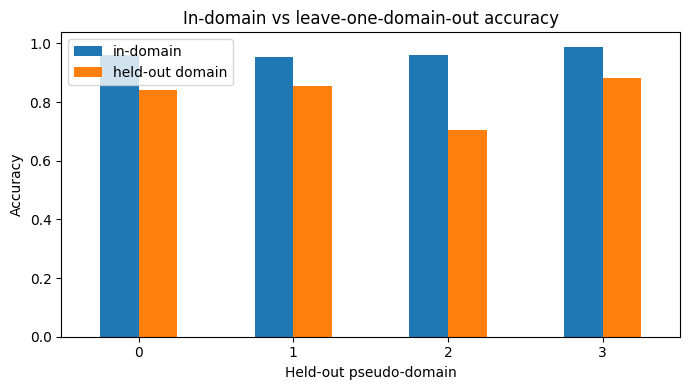

In [36]:
lodo = lodo_report(feats_all, y_all, meta_all["domain"].to_numpy(), seed=SEED)
print(lodo.round(4).to_string(index=False))
print(f"\nMean generalization gap (in-domain minus held-out-domain accuracy): {lodo['generalization_gap'].mean():.4f}")
print("NOTE: frozen-ImageNet-DenseNet + linear head. This is a cheap DIAGNOSTIC of how much "
      "acquisition differences hurt, not a measurement of the hybrid model itself.")

ax = lodo.set_index("group")[["in_domain_acc", "acc"]].plot.bar(figsize=(7, 4), rot=0)
ax.set_ylabel("Accuracy"); ax.set_xlabel("Held-out pseudo-domain")
ax.set_title("In-domain vs leave-one-domain-out accuracy"); ax.legend(["in-domain", "held-out domain"])
plt.tight_layout(); plt.show()
lodo.to_csv(f"{OUT_DIR}/lodo_report.csv", index=False)

### 2c. Scanner-style corruption stress test on the real hybrid model

Each corruption mimics a real acquisition difference: gamma (display/window), multiplicative bias field (coil inhomogeneity), Gaussian noise (lower SNR), blur and low resolution (thicker slices / different matrix), reduced contrast (different sequence parameters).

In [37]:
H = W = IMAGE_SIZE

def _clip(x): return tf.clip_by_value(x, 0.0, 255.0)
def c_gamma(x, g):    return _clip(255.0 * tf.pow(x / 255.0, g))
def c_noise(x, s):    return _clip(x + tf.random.normal(tf.shape(x), stddev=s * 255.0))
def c_blur(x, k):     return tf.nn.avg_pool2d(x, ksize=k, strides=1, padding="SAME")
def c_contrast(x, c):
    m = tf.reduce_mean(x, axis=(1, 2, 3), keepdims=True)
    return _clip(m + c * (x - m))
def c_lowres(x, f):
    small = tf.image.resize(x, (H // f, W // f), method="area")
    return _clip(tf.image.resize(small, (H, W), method="bilinear"))
def c_bias(x, a, grid=4):
    b = tf.shape(x)[0]
    field = tf.random.uniform((b, grid, grid, 1), 1.0 - a, 1.0 + a)
    field = tf.clip_by_value(tf.image.resize(field, (H, W), method="bicubic"), 0.3, 2.0)
    return _clip(x * field)

STRESS = {
    "clean": None,
    "gamma_0.6":   lambda x: c_gamma(x, 0.6),
    "gamma_1.6":   lambda x: c_gamma(x, 1.6),
    "noise_0.03":  lambda x: c_noise(x, 0.03),
    "noise_0.08":  lambda x: c_noise(x, 0.08),
    "blur_3":      lambda x: c_blur(x, 3),
    "blur_7":      lambda x: c_blur(x, 7),
    "lowres_2x":   lambda x: c_lowres(x, 2),
    "lowres_4x":   lambda x: c_lowres(x, 4),
    "contrast_0.6": lambda x: c_contrast(x, 0.6),
    "contrast_0.35": lambda x: c_contrast(x, 0.35),
    "bias_0.25":   lambda x: c_bias(x, 0.25),
    "bias_0.5":    lambda x: c_bias(x, 0.5),
}

def eval_under(model, ds, corrupt_fn, y_true, n_batches=None):
    d = ds if corrupt_fn is None else ds.map(lambda x, y: (corrupt_fn(x), y),
                                             num_parallel_calls=tf.data.AUTOTUNE)
    if n_batches:
        d = d.take(n_batches)
    probs = model.predict(d, verbose=0)
    pred = probs.argmax(1)
    y = np.asarray(y_true)[:len(pred)]
    return dict(acc=float((pred == y).mean()), macro_f1=float(macro_f1(y, pred)),
                tumor_miss=tumor_miss_rate(y, pred)), probs

def run_stress(model, n_batches=None, seed=SEED):
    tf.random.set_seed(seed)
    rows, probs = [], {}
    for name, fn in STRESS.items():
        m, p = eval_under(model, test_ds, fn, test_label_ids, n_batches)
        rows.append({"corruption": name, **m}); probs[name] = p
    return pd.DataFrame(rows).set_index("corruption"), probs

STRESS_N_BATCHES = None     # set e.g. 30 for a quick run (30*BATCH_SIZE images)
hybrid_model.save_weights("hybrid_before_robust.weights.h5")
stress_before, stress_probs_before = run_stress(hybrid_model, STRESS_N_BATCHES)
print(stress_before.round(4).to_string())

                  acc  macro_f1  tumor_miss
corruption                                 
clean          0.9169    0.9163      0.0083
gamma_0.6      0.8675    0.8652      0.0067
gamma_1.6      0.7050    0.7047      0.0133
noise_0.03     0.7994    0.7921      0.0142
noise_0.08     0.7094    0.6950      0.0908
blur_3         0.8244    0.8260      0.0150
blur_7         0.6250    0.5566      0.0767
lowres_2x      0.7906    0.7887      0.0217
lowres_4x      0.6088    0.5230      0.2842
contrast_0.6   0.8925    0.8908      0.0192
contrast_0.35  0.8019    0.7975      0.0492
bias_0.25      0.9125    0.9121      0.0083
bias_0.5       0.9025    0.9032      0.0075


### 2d. Domain-randomization fine-tuning

Short, low-learning-rate fine-tuning of the *already trained* hybrid model with random scanner-style corruptions on the training images. Set `RUN_ROBUST_FINETUNE = False` to skip. The before/after table is the evidence: if robustness doesn't improve, don't claim it.

In [38]:
def random_domain_aug(img):
    """img: single [H, W, 3] float32 image in [0, 255]. Applies random scanner-like corruptions."""
    x = tf.expand_dims(img, 0)
    def maybe(x, fn, p):
        return tf.cond(tf.random.uniform(()) < p, lambda: fn(x), lambda: x)
    x = maybe(x, lambda z: c_gamma(z, tf.exp(tf.random.uniform((), np.log(0.6), np.log(1.6)))), 0.5)
    x = maybe(x, lambda z: c_bias(z, tf.random.uniform((), 0.1, 0.4)), 0.4)
    x = maybe(x, lambda z: c_contrast(z, tf.random.uniform((), 0.6, 1.2)), 0.4)
    x = maybe(x, lambda z: c_blur(z, 3), 0.25)
    x = maybe(x, lambda z: c_lowres(z, 2), 0.2)
    x = maybe(x, lambda z: c_noise(z, tf.random.uniform((), 0.0, 0.06)), 0.4)
    return tf.ensure_shape(tf.squeeze(x, 0), [H, W, 3])

def percentile_stretch(img, lo=1.0, hi=99.0):
    """Optional per-image intensity harmonization (apply identically at train AND test time)."""
    flat = tf.sort(tf.reshape(tf.reduce_mean(img, -1), [-1]))
    n = tf.cast(tf.size(flat) - 1, tf.float32)
    lo_v = flat[tf.cast(lo / 100.0 * n, tf.int32)]
    hi_v = flat[tf.cast(hi / 100.0 * n, tf.int32)]
    return tf.clip_by_value((img - lo_v) / (hi_v - lo_v + 1e-6), 0.0, 1.0) * 255.0

def make_robust_dataset(paths, labels, training, stretch=False, batch_size=BATCH_SIZE):
    ids = [CLASS_TO_IDX[l] for l in labels]
    ds = tf.data.Dataset.from_tensor_slices((list(paths), ids))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(_load_image, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(lambda x, y: (random_domain_aug(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    if stretch:
        ds = ds.map(lambda x, y: (percentile_stretch(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

RUN_ROBUST_FINETUNE = True
ROBUST_EPOCHS = 8

if RUN_ROBUST_FINETUNE:
    robust_train_ds = make_robust_dataset(train_paths, train_labels, training=True)
    hybrid_model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                         loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    hybrid_model.fit(
        robust_train_ds, validation_data=val_ds, epochs=ROBUST_EPOCHS, class_weight=class_weights,
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
                   tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7)])
    hybrid_model.save_weights("hybrid_robust.weights.h5")
    stress_after, stress_probs_after = run_stress(hybrid_model, STRESS_N_BATCHES)
else:
    stress_after, stress_probs_after = stress_before, stress_probs_before

cmp = stress_before[["acc", "tumor_miss"]].join(stress_after[["acc", "tumor_miss"]],
                                               lsuffix="_before", rsuffix="_after")
cmp["acc_delta"] = cmp["acc_after"] - cmp["acc_before"]
print(cmp.round(4).to_string())
print(f"\nMean accuracy over corruptions: before {stress_before['acc'].mean():.4f} -> after {stress_after['acc'].mean():.4f}")
cmp.to_csv(f"{OUT_DIR}/stress_before_after.csv")

Epoch 1/8
298/298 ━━━━━━━━━━━━━━━━━━━━ 297s 696ms/step - accuracy: 0.8536 - loss: 0.4133 - val_accuracy: 0.9405 - val_loss: 0.1601 - learning_rate: 1.0000e-05
Epoch 2/8
298/298 ━━━━━━━━━━━━━━━━━━━━ 118s 394ms/step - accuracy: 0.8664 - loss: 0.3662 - val_accuracy: 0.9381 - val_loss: 0.1801 - learning_rate: 1.0000e-05
Epoch 3/8
298/298 ━━━━━━━━━━━━━━━━━━━━ 117s 393ms/step - accuracy: 0.8828 - loss: 0.3223 - val_accuracy: 0.9464 - val_loss: 0.1548 - learning_rate: 1.0000e-05
Epoch 4/8
298/298 ━━━━━━━━━━━━━━━━━━━━ 117s 394ms/step - accuracy: 0.8853 - loss: 0.3145 - val_accuracy: 0.9476 - val_loss: 0.1416 - learning_rate: 1.0000e-05
Epoch 5/8
298/298 ━━━━━━━━━━━━━━━━━━━━ 118s 395ms/step - accuracy: 0.8901 - loss: 0.3058 - val_accuracy: 0.9500 - val_loss: 0.1461 - learning_rate: 1.0000e-05
Epoch 6/8
298/298 ━━━━━━━━━━━━━━━━━━━━ 118s 395ms/step - accuracy: 0.9040 - loss: 0.2760 - val_accuracy: 0.9512 - val_loss: 0.1387 - learning_rate: 1.0000e-05
Epoch 7/8
298/298 ━━━━━━━━━━━━━━━━━━━━ 118s 39

---
## 21. Uncertainty, calibration and selective prediction (Gaps 4, 5, 6)

Doctors distrust a model that is always confident. This section makes the model say *when it doesn't know*:

* **Temperature scaling** fixes over-confidence (fit on validation, evaluated on test).
* **Ensemble disagreement** (hybrid + six standalone models) gives an *epistemic* uncertainty estimate. *(MC-Dropout is deliberately not used: calling this model with `training=True` would also switch every BatchNorm layer to batch statistics and corrupt the predictions.)*
* **Selective prediction** defers low-confidence cases to the radiologist. The threshold is picked on validation using an exact binomial *lower confidence bound*, not a lucky point estimate.
* **Sensitivity-first "no tumor" rule:** the false-positive / false-negative asymmetry is made explicit. "No tumor" is only suggested when `P(notumor)` clears a threshold chosen to hit a target tumor sensitivity.
* **Conformal prediction sets** give a statistical coverage guarantee (under exchangeability) and an automatic "this case is ambiguous" signal when the set has several classes. The notebook then **shows the guarantee degrading under domain shift**.

In [39]:
def logits_from_probs(p):
    return np.log(np.clip(p, 1e-8, 1.0))

def apply_temperature(p, T):
    return softmax_np(logits_from_probs(p) / T)

def nll(p, y):
    return float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-12, 1.0)).mean())

def brier(p, y):
    return float(((p - np.eye(p.shape[1])[y]) ** 2).sum(1).mean())

def fit_temperature(p_val, y_val):
    lg = logits_from_probs(p_val)
    res = minimize_scalar(lambda t: nll(softmax_np(lg / np.exp(t)), y_val), bounds=(-3, 3), method="bounded")
    return float(np.exp(res.x))

def ece(p, y, n_bins=15):
    conf, correct = p.max(1), (p.argmax(1) == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(e)

def reliability_curve(p, y, n_bins=10):
    conf, correct = p.max(1), (p.argmax(1) == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    bc, ba, cnt = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            bc.append(conf[m].mean()); ba.append(correct[m].mean()); cnt.append(int(m.sum()))
    return np.array(bc), np.array(ba), np.array(cnt)

def _entropy(q):
    return -(q * np.log(np.clip(q, 1e-12, 1.0))).sum(-1)

def ensemble_uncertainty(prob_list):
    """Returns mean probs, total entropy, aleatoric (expected entropy), epistemic (mutual information)."""
    P = np.stack(prob_list)                    # [M, N, C]
    mean = P.mean(0)
    total = _entropy(mean)
    aleatoric = _entropy(P).mean(0)
    return mean, total, aleatoric, np.maximum(total - aleatoric, 0.0)

def threshold_for_target_acc(conf, correct, target=0.99, alpha=0.05, use_lcb=True):
    """Smallest confidence threshold (= max coverage) whose selective accuracy (lower bound) >= target."""
    for t in np.unique(conf):
        m = conf >= t
        n, k = int(m.sum()), int(correct[m].sum())
        score = clopper_pearson_lower(k, n, alpha) if use_lcb else k / n
        if score >= target:
            return float(t)
    return None

def risk_coverage(conf, correct):
    o = np.argsort(-conf, kind="stable")
    c = correct[o].astype(float)
    n = np.arange(1, len(c) + 1)
    return n / len(c), 1.0 - np.cumsum(c) / n

def choose_notumor_threshold(p_notumor, y, notumor_idx, target_sens=0.99):
    """Pick tau so that 'notumor' is only suggested when P(notumor) >= tau and
    tumor sensitivity (true tumors NOT suggested as notumor) >= target on the calibration set."""
    pn_t = p_notumor[y != notumor_idx]
    if len(pn_t) == 0:
        return None, float("nan")
    q = np.quantile(pn_t, target_sens, method="higher")
    tau = float(min(np.nextafter(q, 1.0), 1.0))
    return tau, float((pn_t < tau).mean())

def apply_triage(p, tau, notumor_idx):
    cleared = p[:, notumor_idx] >= tau
    q = p.copy(); q[:, notumor_idx] = -1.0
    return np.where(cleared, notumor_idx, q.argmax(1)), cleared

def conformal_threshold(p_cal, y_cal, alpha=0.05):
    n = len(y_cal)
    s = 1.0 - p_cal[np.arange(n), y_cal]
    level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    return float(np.quantile(s, level, method="higher"))

def conformal_sets(p, q):
    return p >= (1.0 - q)

def conformal_eval(sets, y):
    return dict(coverage=float(sets[np.arange(len(y)), y].mean()),
                avg_set_size=float(sets.sum(1).mean()),
                empty_frac=float((sets.sum(1) == 0).mean()),
                ambiguous_frac=float((sets.sum(1) > 1).mean()))

Temperature: hybrid T=1.18, ensemble T=0.50   (T>1 means the raw model was over-confident)
          model    acc    NLL  Brier    ECE
     hybrid raw 0.9112 0.3680 0.1361 0.0409
  hybrid + temp 0.9112 0.3320 0.1336 0.0312
   ensemble raw 0.8769 0.4010 0.1884 0.0612
ensemble + temp 0.8769 0.4495 0.1804 0.0370


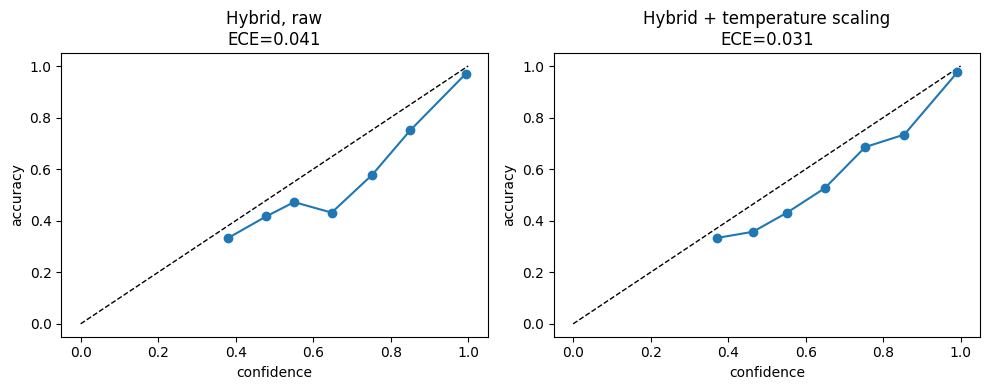


Error-detection AUROC  (epistemic / mutual information): 0.825
Error-detection AUROC  (1 - max calibrated prob)        : 0.893
(0.5 = useless, 1.0 = perfect. Useful uncertainty should be clearly above 0.5.)


In [40]:
# ----- predictions from every member (hybrid is the CURRENT model, i.e. after robust fine-tuning) -----
hyb_val  = predict_probs(hybrid_model, val_paths,  val_labels)
hyb_test = predict_probs(hybrid_model, test_paths, test_labels)
members_val = {"hybrid": hyb_val}
for n, m in baseline_models.items():
    members_val[n] = predict_probs(m, val_paths, val_labels)
members_test = {"hybrid": hyb_test, **baseline_test_probs}

ens_val,  _, _, _        = ensemble_uncertainty(list(members_val.values()))
ens_test, tot_u, ale_u, epi_u = ensemble_uncertainty(list(members_test.values()))

T_h = fit_temperature(hyb_val, val_label_ids)
T_e = fit_temperature(ens_val, val_label_ids)
hyb_val_c,  hyb_test_c  = apply_temperature(hyb_val, T_h),  apply_temperature(hyb_test, T_h)
ens_val_c,  ens_test_c  = apply_temperature(ens_val, T_e),  apply_temperature(ens_test, T_e)

rows = []
for name, p in [("hybrid raw", hyb_test), ("hybrid + temp", hyb_test_c),
                ("ensemble raw", ens_test), ("ensemble + temp", ens_test_c)]:
    rows.append(dict(model=name, acc=(p.argmax(1) == test_label_ids).mean(), NLL=nll(p, test_label_ids),
                     Brier=brier(p, test_label_ids), ECE=ece(p, test_label_ids)))
print(f"Temperature: hybrid T={T_h:.2f}, ensemble T={T_e:.2f}   (T>1 means the raw model was over-confident)")
print(pd.DataFrame(rows).round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, p) in zip(axes, [("Hybrid, raw", hyb_test), ("Hybrid + temperature scaling", hyb_test_c)]):
    bc, ba, cnt = reliability_curve(p, test_label_ids)
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.plot(bc, ba, "o-")
    ax.set_title(f"{title}\nECE={ece(p, test_label_ids):.3f}"); ax.set_xlabel("confidence"); ax.set_ylabel("accuracy")
plt.tight_layout(); plt.show()

# Does uncertainty actually flag mistakes?
err = (ens_test.argmax(1) != test_label_ids)
if 0 < err.sum() < len(err):
    print(f"\nError-detection AUROC  (epistemic / mutual information): {roc_auc_score(err, epi_u):.3f}")
    print(f"Error-detection AUROC  (1 - max calibrated prob)        : {roc_auc_score(err, 1 - ens_test_c.max(1)):.3f}")
    print("(0.5 = useless, 1.0 = perfect. Useful uncertainty should be clearly above 0.5.)")

[Selective prediction] confidence threshold = 0.9963
  answered by AI : 44.4% of test cases   | deferred to radiologist: 55.6%
  accuracy on answered cases : 0.9958  (95% CI 0.9877-0.9991)
  accuracy if forced to answer everything : 0.8769


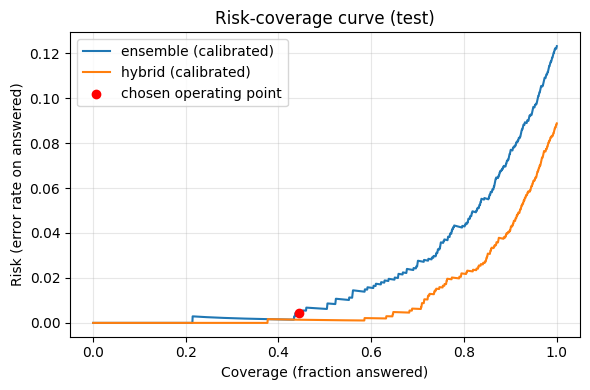


[Sensitivity-first rule] suggest 'no tumor' only if P(notumor) >= 0.3784  (val sensitivity 0.990)
  tumor sensitivity (test)  : 0.9375  95% CI (0.9222826603833819, 0.9505259371440399)
  specificity (normals suggested 'no tumor'): 0.9975  95% CI (0.9861502300379867, 0.9999367074830952)

[Combined policy: defer if low confidence, else sensitivity-first triage]
  deferred: 55.6% | accuracy on answered: 0.9958 | tumor-miss on answered: 0.0054


In [41]:
TARGET_SELECTIVE_ACC = 0.99     # accuracy we want on the cases the model answers
TARGET_TUMOR_SENS    = 0.99     # sensitivity we want for "tumor present"

conf_val  = ens_val_c.max(1);  correct_val  = (ens_val_c.argmax(1)  == val_label_ids)
conf_test = ens_test_c.max(1); correct_test = (ens_test_c.argmax(1) == test_label_ids)

tau = threshold_for_target_acc(conf_val, correct_val, TARGET_SELECTIVE_ACC, use_lcb=True)
if tau is None:
    print("No threshold reaches the target with a confidence-bound guarantee on validation; using point estimate.")
    tau = threshold_for_target_acc(conf_val, correct_val, TARGET_SELECTIVE_ACC, use_lcb=False)
if tau is None:
    tau = 1.0

accept = conf_test >= tau
k, n = int(correct_test[accept].sum()), int(accept.sum())
lo, hi = clopper_pearson(k, n)
print(f"[Selective prediction] confidence threshold = {tau:.4f}")
print(f"  answered by AI : {accept.mean():.1%} of test cases   | deferred to radiologist: {(~accept).mean():.1%}")
print(f"  accuracy on answered cases : {k/max(n,1):.4f}  (95% CI {lo:.4f}-{hi:.4f})")
print(f"  accuracy if forced to answer everything : {correct_test.mean():.4f}")

cov, risk = risk_coverage(conf_test, correct_test)
cov_h, risk_h = risk_coverage(hyb_test_c.max(1), hyb_test_c.argmax(1) == test_label_ids)
plt.figure(figsize=(6, 4))
plt.plot(cov, risk, label="ensemble (calibrated)"); plt.plot(cov_h, risk_h, label="hybrid (calibrated)")
plt.scatter([accept.mean()], [1 - k / max(n, 1)], c="red", zorder=5, label="chosen operating point")
plt.xlabel("Coverage (fraction answered)"); plt.ylabel("Risk (error rate on answered)")
plt.title("Risk-coverage curve (test)"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

# ---- sensitivity-first "no tumor" rule ----
tau_n, sens_val = choose_notumor_threshold(ens_val_c[:, NOTUMOR], val_label_ids, NOTUMOR, TARGET_TUMOR_SENS)
tri_pred, cleared = apply_triage(ens_test_c, tau_n, NOTUMOR)
is_tumor = test_label_ids != NOTUMOR
sens_k, sens_n = int((~cleared[is_tumor]).sum()), int(is_tumor.sum())
spec_k, spec_n = int(cleared[~is_tumor].sum()), int((~is_tumor).sum())
print(f"\n[Sensitivity-first rule] suggest 'no tumor' only if P(notumor) >= {tau_n:.4f}  (val sensitivity {sens_val:.3f})")
print(f"  tumor sensitivity (test)  : {sens_k/sens_n:.4f}  95% CI {clopper_pearson(sens_k, sens_n)}")
print(f"  specificity (normals suggested 'no tumor'): {spec_k/spec_n:.4f}  95% CI {clopper_pearson(spec_k, spec_n)}")

# ---- combined policy ----
answer = accept
final_pred = tri_pred
print("\n[Combined policy: defer if low confidence, else sensitivity-first triage]")
print(f"  deferred: {(~answer).mean():.1%} | accuracy on answered: {(final_pred[answer] == test_label_ids[answer]).mean():.4f}"
      f" | tumor-miss on answered: {tumor_miss_rate(test_label_ids[answer], final_pred[answer]):.4f}")

In [42]:
ALPHA = 0.05
q_hat = conformal_threshold(hyb_val_c, val_label_ids, ALPHA)
sets_clean = conformal_sets(hyb_test_c, q_hat)
res = conformal_eval(sets_clean, test_label_ids)
print(f"Conformal (alpha={ALPHA}, target coverage {1-ALPHA:.0%}) on CLEAN test data: {res}")
print("Cases whose set has >1 class are 'ambiguous' and should go to a human. Empty sets = nothing is plausible = defer.\n")

rows = []
for name, P in stress_probs_after.items():
    y = test_label_ids[:len(P)]
    r = conformal_eval(conformal_sets(apply_temperature(P, T_h), q_hat), y)
    rows.append(dict(corruption=name, **r))
shift = pd.DataFrame(rows).set_index("corruption")
print(shift.round(3).to_string())
print(f"\nThe guarantee holds only if test data look like calibration data. "
      f"Worst coverage under shift: {shift['coverage'].min():.3f} (target {1-ALPHA:.2f}). "
      f"This is why a domain-shift monitor (section 7) is necessary.")
shift.to_csv(f"{OUT_DIR}/conformal_under_shift.csv")

Conformal (alpha=0.05, target coverage 95%) on CLEAN test data: {'coverage': 0.896875, 'avg_set_size': 0.968125, 'empty_frac': 0.031875, 'ambiguous_frac': 0.0}
Cases whose set has >1 class are 'ambiguous' and should go to a human. Empty sets = nothing is plausible = defer.

               coverage  avg_set_size  empty_frac  ambiguous_frac
corruption                                                       
clean             0.897         0.968       0.032             0.0
gamma_0.6         0.886         0.959       0.041             0.0
gamma_1.6         0.869         0.948       0.052             0.0
noise_0.03        0.891         0.959       0.041             0.0
noise_0.08        0.817         0.929       0.071             0.0
blur_3            0.898         0.965       0.035             0.0
blur_7            0.826         0.910       0.090             0.0
lowres_2x         0.899         0.966       0.034             0.0
lowres_4x         0.792         0.898       0.102             0.0

### 3b. A note on rare / atypical cases (Gap 5)

Nothing here lets the model *recognize* a tumor type it never saw. What it can do is **notice it is out of its depth**: high epistemic uncertainty, ambiguous conformal sets, or low calibrated confidence all route the case to a human. Treat those routed cases as your pipeline for collecting rare-case data: review them, label them, and feed them back.

---
## 22. Explainability that is actually correct (Gap 4)

The original Grad-CAM took a gradient of `densenet_backbone.output[:, pred_index]`. That output is the 1024-d pooled feature vector, so `pred_index` selected a *feature channel*, not a class, and the input was preprocessed twice. 

The version below differentiates the **final class logit of the full hybrid model** with respect to DenseNet's last 4-D feature map (re-running the fusion head by hand), and it **verifies** its reconstruction against `hybrid_model` before use. A **deletion test** then checks the heatmaps are *faithful*: removing the pixels Grad-CAM calls important should hurt the prediction more than removing random pixels.

> Only the DenseNet branch is explained. The other five branches also influence the output, so this heatmap is a partial explanation. Say so if you show it to clinicians.

In [43]:
def _trapz(y, x):
    y, x = np.asarray(y, float), np.asarray(x, float)
    return float(np.sum((y[1:] + y[:-1]) * (x[1:] - x[:-1])) / 2.0)

def deletion_curve(predict_fn, img, heat, class_idx, steps=11):
    """Delete (fill with the image mean) the most salient pixels first; track P(class)."""
    Hh, Ww = heat.shape
    order = np.argsort(-heat.ravel(), kind="stable")
    fill = float(img.mean())
    fracs = np.linspace(0, 1, steps)
    batch = []
    for f in fracs:
        k = int(round(f * Hh * Ww))
        flat = img.reshape(-1, img.shape[-1]).copy()
        flat[order[:k]] = fill
        batch.append(flat.reshape(img.shape))
    return fracs, predict_fn(np.stack(batch))[:, class_idx]

def deletion_auc(predict_fn, img, heat, class_idx, steps=11):
    fr, p = deletion_curve(predict_fn, img, heat, class_idx, steps)
    return _trapz(p, fr)       # LOWER = better (prediction collapses quickly)

Grad-CAM reconstruction matches hybrid_model (max abs diff 5.96e-07).


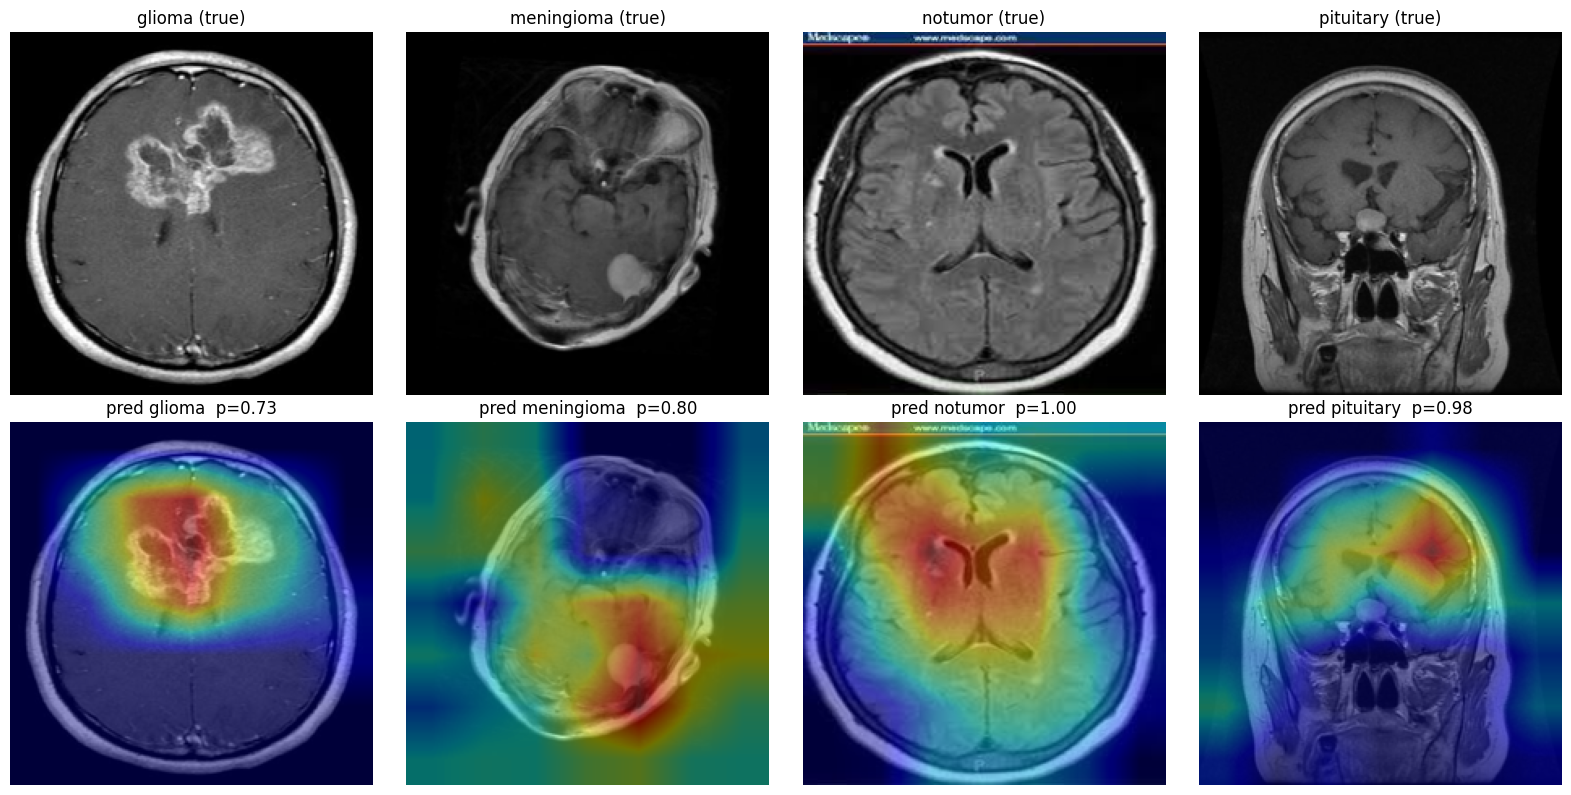

In [44]:
FUSION_ORDER = ["custom", "mednet", "vgg16", "resnet50", "dense", "efficientnetb3"]

def build_gradcam_parts(model, branch_name="densenet121_branch"):
    branch = model.get_layer(branch_name)
    prefix = branch_name.replace("_branch", "")
    backbone = next(l for l in branch.layers if isinstance(l, tf.keras.Model))
    fmap_layer = backbone.layers[-2]                 # last 4-D map, just before global pooling
    assert len(fmap_layer.output.shape) == 4, "unexpected DenseNet structure"
    parts = dict(
        pre=branch.get_layer(f"{prefix}_preprocess"),
        conv_model=tf.keras.Model(backbone.input, fmap_layer.output),
        proj=branch.get_layer(f"{prefix}_projection"),
        proj_bn=branch.get_layer(f"{prefix}_projection_bn"),
        proj_do=branch.get_layer(f"{prefix}_projection_dropout"),
    )
    others = {
        "custom": tf.keras.Model(model.input, model.get_layer("customcnn_proj_drop").output),
        "mednet": tf.keras.Model(model.input, model.get_layer("mednet_proj_drop").output),
        "vgg16": model.get_layer("vgg16_branch"),
        "resnet50": model.get_layer("resnet50_branch"),
        "efficientnetb3": model.get_layer("efficientnetb3_branch"),
    }
    return parts, others

def gradcam_v2(model, parts, others, img_raw, class_idx=None):
    """img_raw: [H, W, 3] float32 in [0, 255] (the hybrid model preprocesses internally)."""
    x = tf.convert_to_tensor(img_raw[None].astype(np.float32))
    feats = {k: m(x, training=False) for k, m in others.items()}
    fmap = parts["conv_model"](parts["pre"](x), training=False)
    W, b = model.get_layer("predictions").get_weights()
    with tf.GradientTape() as tape:
        tape.watch(fmap)
        d = tf.reduce_mean(fmap, axis=[1, 2])
        d = parts["proj"](d)
        d = parts["proj_bn"](d, training=False)
        d = parts["proj_do"](d, training=False)
        feats["dense"] = d
        z = model.get_layer("fusion_concat")([feats[k] for k in FUSION_ORDER])
        z = model.get_layer("fusion_dense1")(z)
        z = model.get_layer("fusion_bn1")(z, training=False)
        z = model.get_layer("fusion_drop1")(z, training=False)
        z = model.get_layer("fusion_dense2")(z)
        z = model.get_layer("fusion_drop2")(z, training=False)
        logits = tf.matmul(z, W) + b
        probs = tf.nn.softmax(logits)
        if class_idx is None:
            class_idx = int(tf.argmax(probs[0]))
        score = logits[0, class_idx]               # pre-softmax logit: no saturation
    grads = tape.gradient(score, fmap)
    w = tf.reduce_mean(grads, axis=[1, 2], keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(w * fmap, axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[None, ..., None], (IMAGE_SIZE, IMAGE_SIZE), method="bilinear")[0, :, :, 0]
    return cam.numpy(), class_idx, probs.numpy()[0]

def load_raw(path):
    return np.asarray(Image.open(path).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE)), dtype=np.float32)

gc_parts, gc_others = build_gradcam_parts(hybrid_model)

# Safety check: my manual forward pass must reproduce hybrid_model exactly.
_img = load_raw(test_paths[0])
_, _, p_rec = gradcam_v2(hybrid_model, gc_parts, gc_others, _img)
p_ref = hybrid_model.predict(_img[None], verbose=0)[0]
_err = float(np.abs(p_rec - p_ref).max())
assert _err < 1e-3, f"Grad-CAM reconstruction mismatch (max abs diff {_err:.2e}); do not trust the heatmaps."
print(f"Grad-CAM reconstruction matches hybrid_model (max abs diff {_err:.2e}).")

def show_gradcam_v2(paths_, alpha=0.45):
    fig, axes = plt.subplots(2, len(paths_), figsize=(4 * len(paths_), 8))
    for j, pth in enumerate(paths_):
        img = load_raw(pth)
        heat, c, pr = gradcam_v2(hybrid_model, gc_parts, gc_others, img)
        overlay = np.clip((1 - alpha) * img / 255.0 + alpha * plt.cm.jet(heat)[..., :3], 0, 1)
        axes[0, j].imshow(img / 255.0); axes[0, j].axis("off")
        axes[0, j].set_title(os.path.basename(os.path.dirname(pth)) + " (true)")
        axes[1, j].imshow(overlay); axes[1, j].axis("off")
        axes[1, j].set_title(f"pred {CLASS_NAMES[c]}  p={pr[c]:.2f}")
    plt.tight_layout(); plt.show()

show_gradcam_v2([test_paths[int(np.where(test_label_ids == c)[0][0])] for c in range(NUM_CLASSES)])

In [45]:
# Faithfulness (deletion) test: Grad-CAM vs random pixel order. Lower AUC = more faithful.
rng = np.random.default_rng(SEED)
N_PER_CLASS = 10
idx = np.concatenate([rng.choice(np.where(test_label_ids == c)[0], N_PER_CLASS, replace=False)
                      for c in range(NUM_CLASSES)])
pred_fn = lambda b: hybrid_model.predict(b, verbose=0)

auc_cam, auc_rand = [], []
for i in idx:
    img = load_raw(test_paths[i])
    heat, c, _ = gradcam_v2(hybrid_model, gc_parts, gc_others, img)
    auc_cam.append(deletion_auc(pred_fn, img, heat, c))
    auc_rand.append(deletion_auc(pred_fn, img, rng.random(heat.shape), c))
auc_cam, auc_rand = np.array(auc_cam), np.array(auc_rand)
print(f"Deletion AUC  Grad-CAM: {auc_cam.mean():.3f}   random: {auc_rand.mean():.3f}   (lower is better)")
print(f"Grad-CAM beats random on {(auc_cam < auc_rand).mean():.0%} of {len(idx)} images")
print("If Grad-CAM is NOT clearly better than random, do not present these heatmaps as explanations.")

2026-10-24 15:46:02.106992: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:46:02.247132: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:46:02.590798: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:46:02.740111: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:46:03.561028: E external/local_xla/xla/stream_

Deletion AUC  Grad-CAM: 0.485   random: 0.486   (lower is better)
Grad-CAM beats random on 52% of 40 images
If Grad-CAM is NOT clearly better than random, do not present these heatmaps as explanations.


---
## 23. Compute and deployment (Gap 7)

Six backbones at once will not run on a hospital workstation. The standard fix is **knowledge distillation**: train one small network (EfficientNet-B0, ~4M parameters) to imitate the ensemble's *soft* predictions, then export to **TFLite** with dynamic-range quantization. The table at the end compares size, CPU latency and accuracy. Choose by the numbers, not by hope: if the student loses clinically meaningful accuracy or sensitivity, keep the larger model.

In [46]:
from tensorflow.keras import layers
from tensorflow.keras.applications import efficientnet

TEACHER_ALPHA = 0.5      # weight of the hard label in the target
TEACHER_TEMP  = 2.0      # >1 softens teacher probabilities

def soften(p, T):
    q = np.clip(p, 1e-8, 1.0) ** (1.0 / T)
    return q / q.sum(1, keepdims=True)

# Teacher = mean probability of hybrid + all standalone models, on the (un-augmented) training images.
teacher_members = [hybrid_model] + list(baseline_models.values())
teacher_train = np.mean([predict_probs(m, train_paths, train_labels) for m in teacher_members], axis=0)
soft_train = TEACHER_ALPHA * np.eye(NUM_CLASSES)[train_ids] + (1 - TEACHER_ALPHA) * soften(teacher_train, TEACHER_TEMP)
soft_val = np.eye(NUM_CLASSES)[val_label_ids]
print("Teacher accuracy on train images:", (teacher_train.argmax(1) == train_ids).mean().round(4))

def make_soft_dataset(paths, soft, training, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((list(paths), soft.astype("float32")))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(_load_image, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(lambda x, y: (random_domain_aug(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

def build_student():
    inp = layers.Input((IMAGE_SIZE, IMAGE_SIZE, 3), name="student_input")
    try:
        base = efficientnet.EfficientNetB0(include_top=False, weights="imagenet",
                                           input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), pooling="avg")
    except Exception as e:
        print("ImageNet weights unavailable for EfficientNetB0 (", e, ") -> training from scratch; expect lower accuracy.")
        base = efficientnet.EfficientNetB0(include_top=False, weights=None,
                                           input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), pooling="avg")
    x = base(inp)                                   # EfficientNet rescales [0,255] internally
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32", name="student_out")(x)
    return tf.keras.Model(inp, out, name="student_effnetb0"), base

student, student_base = build_student()
sd_train = make_soft_dataset(train_paths, soft_train, training=True)
sd_val   = make_soft_dataset(val_paths,   soft_val,   training=False)
es = lambda: tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True)

student_base.trainable = False
student.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
student.fit(sd_train, validation_data=sd_val, epochs=6, callbacks=[es()])

student_base.trainable = True
for l in student_base.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False
student.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss="categorical_crossentropy", metrics=["accuracy"])
student.fit(sd_train, validation_data=sd_val, epochs=15, callbacks=[es()])
student.save_weights(f"{OUT_DIR}/student.weights.h5")

Teacher accuracy on train images: 0.9458
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/6


2026-10-24 15:50:16.232302: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:50:16.371563: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:50:16.703870: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:50:16.846453: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:50:17.628349: E external/local_xla/xla/stream_

297/298 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.6179 - loss: 1.0431

2026-10-24 15:51:03.886985: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:51:04.023154: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:51:04.346625: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:51:04.489082: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:51:05.254780: E external/local_xla/xla/stream_

298/298 ━━━━━━━━━━━━━━━━━━━━ 84s 200ms/step - accuracy: 0.7145 - loss: 0.9127 - val_accuracy: 0.8274 - val_loss: 0.5288
Epoch 2/6
298/298 ━━━━━━━━━━━━━━━━━━━━ 35s 116ms/step - accuracy: 0.8155 - loss: 0.7902 - val_accuracy: 0.8429 - val_loss: 0.4906
Epoch 3/6
298/298 ━━━━━━━━━━━━━━━━━━━━ 35s 115ms/step - accuracy: 0.8315 - loss: 0.7709 - val_accuracy: 0.8524 - val_loss: 0.4501
Epoch 4/6
298/298 ━━━━━━━━━━━━━━━━━━━━ 34s 115ms/step - accuracy: 0.8389 - loss: 0.7655 - val_accuracy: 0.8643 - val_loss: 0.4362
Epoch 5/6
298/298 ━━━━━━━━━━━━━━━━━━━━ 35s 116ms/step - accuracy: 0.8420 - loss: 0.7561 - val_accuracy: 0.8595 - val_loss: 0.4302
Epoch 6/6
298/298 ━━━━━━━━━━━━━━━━━━━━ 34s 115ms/step - accuracy: 0.8506 - loss: 0.7526 - val_accuracy: 0.8631 - val_loss: 0.4367
Epoch 1/15


2026-10-24 15:54:43.981684: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:54:44.123262: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


297/298 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.8559 - loss: 0.7526

2026-10-24 15:55:48.258076: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:55:48.395020: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:55:51.648345: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 15:55:51.784367: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


298/298 ━━━━━━━━━━━━━━━━━━━━ 124s 253ms/step - accuracy: 0.8878 - loss: 0.7083 - val_accuracy: 0.9524 - val_loss: 0.2963
Epoch 2/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 79s 135ms/step - accuracy: 0.9338 - loss: 0.6521 - val_accuracy: 0.9321 - val_loss: 0.2873
Epoch 3/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 40s 134ms/step - accuracy: 0.9567 - loss: 0.6377 - val_accuracy: 0.9726 - val_loss: 0.2518
Epoch 4/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 40s 134ms/step - accuracy: 0.9674 - loss: 0.6249 - val_accuracy: 0.9714 - val_loss: 0.2432
Epoch 5/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 40s 134ms/step - accuracy: 0.9723 - loss: 0.6210 - val_accuracy: 0.9833 - val_loss: 0.2028
Epoch 6/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 41s 133ms/step - accuracy: 0.9761 - loss: 0.6146 - val_accuracy: 0.9857 - val_loss: 0.1900
Epoch 7/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 40s 133ms/step - accuracy: 0.9836 - loss: 0.6098 - val_accuracy: 0.9881 - val_loss: 0.1987
Epoch 8/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 40s 133ms/step - accuracy: 0.9891 - loss: 0.6059 - va

In [47]:
def latency_ms(fn, x, n=15, warm=3):
    for _ in range(warm):
        fn(x)
    ts = []
    for _ in range(n):
        t = time.perf_counter(); fn(x); ts.append((time.perf_counter() - t) * 1000)
    return float(np.median(ts))

# --- TFLite, dynamic-range quantization ---
tfl_bytes = None
try:
    conv = tf.lite.TFLiteConverter.from_keras_model(student)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    tfl_bytes = conv.convert()
    open(f"{OUT_DIR}/student_dynamic_quant.tflite", "wb").write(tfl_bytes)
except Exception as e:
    print("TFLite conversion failed:", e)

def tflite_predict(model_bytes, X):
    it = tf.lite.Interpreter(model_content=model_bytes); it.allocate_tensors()
    i_in, i_out = it.get_input_details()[0], it.get_output_details()[0]
    P = np.empty((len(X), i_out["shape"][-1]), np.float32)
    for i in range(len(X)):
        it.set_tensor(i_in["index"], X[i:i + 1].astype(np.float32)); it.invoke()
        P[i] = it.get_tensor(i_out["index"])[0]
    return P

# first 25 batches of the test set held in memory for the TFLite check
X_sub = np.concatenate([x.numpy() for x, _ in test_ds.take(25)])
y_sub = test_label_ids[:len(X_sub)]

student_test = student.predict(test_ds, verbose=0)
rows = [dict(model="hybrid (6 backbones)", params_M=hybrid_model.count_params() / 1e6,
             size_MB=hybrid_model.count_params() * 4 / 1e6, acc=(hyb_test.argmax(1) == test_label_ids).mean(),
             tumor_miss=tumor_miss_rate(test_label_ids, hyb_test.argmax(1))),
        dict(model="student (EffNet-B0)", params_M=student.count_params() / 1e6,
             size_MB=student.count_params() * 4 / 1e6, acc=(student_test.argmax(1) == test_label_ids).mean(),
             tumor_miss=tumor_miss_rate(test_label_ids, student_test.argmax(1)))]
x1 = np.zeros((1, IMAGE_SIZE, IMAGE_SIZE, 3), np.float32)
with tf.device("/CPU:0"):
    rows[0]["cpu_latency_ms"] = latency_ms(lambda a: hybrid_model(a, training=False), x1, n=8)
    rows[1]["cpu_latency_ms"] = latency_ms(lambda a: student(a, training=False), x1)
if tfl_bytes is not None:
    P_tfl = tflite_predict(tfl_bytes, X_sub)
    it = tf.lite.Interpreter(model_content=tfl_bytes); it.allocate_tensors()
    i_in, i_out = it.get_input_details()[0], it.get_output_details()[0]
    def _one(a):
        it.set_tensor(i_in["index"], a); it.invoke(); return it.get_tensor(i_out["index"])
    rows.append(dict(model="student TFLite int8-dynamic", params_M=student.count_params() / 1e6,
                     size_MB=len(tfl_bytes) / 1e6, acc=(P_tfl.argmax(1) == y_sub).mean(),
                     tumor_miss=tumor_miss_rate(y_sub, P_tfl.argmax(1)),
                     cpu_latency_ms=latency_ms(_one, x1)))
deploy = pd.DataFrame(rows).set_index("model")
print(deploy.round(4).to_string())
print("\nTFLite row's accuracy is on the first", len(X_sub), "test images only. "
      "Latencies are indicative (single image, this machine's CPU).")
deploy.to_csv(f"{OUT_DIR}/deployment_table.csv")

INFO:tensorflow:Assets written to: /tmp/tmpezkctunz/assets


INFO:tensorflow:Assets written to: /tmp/tmpezkctunz/assets


Saved artifact at '/tmp/tmpezkctunz'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='student_input')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  132830140619792: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  132830140620752: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  132829875380752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132833561770320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132833561766864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132829875378640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132829875382672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132833561983504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132833561760528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132833561766672: TensorSpec(shape=(), dtype=tf.resource, name=Non

W0000 00:00:1792857912.245516      49 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792857912.245571      49 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792857912.448483      49 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


                             params_M   size_MB     acc  tumor_miss  cpu_latency_ms
model                                                                              
hybrid (6 backbones)          59.5532  238.2129  0.9112      0.0208       1969.6111
student (EffNet-B0)            4.0547   16.2188  0.9444      0.0308        371.6167
student TFLite int8-dynamic    4.0547    4.5541  0.8175      0.0850         31.8653

TFLite row's accuracy is on the first 400 test images only. Latencies are indicative (single image, this machine's CPU).


---
## 24. From 2D slices to patient-level, multi-sequence, 3D (Gaps 2 and 3)

**Hard limit, stated plainly:** the Kaggle dataset has *no patient IDs*, *no slice order* and a *single sequence*. You cannot measure patient-level or multi-modal performance on it, and nothing here pretends otherwise. What this section gives you is **tested, ready-to-plug-in tooling** for when you have the right data:

| Need | Where to get it (verify each licence/access process yourself) |
|---|---|
| Multi-sequence volumes with segmentations, many institutions | BraTS challenge data (T1, T1ce, T2, FLAIR) |
| Molecular / grade labels | RSNA-MICCAI BraTS 2021 (MGMT), BraTS 2019 (HGG vs LGG), UCSF-PDGM (IDH, grade) |
| Large multi-institution archives | The Cancer Imaging Archive (TCIA) |
| The real thing | Your own hospital's PACS export under ethics approval |

The Figshare "Cheng" brain-tumor set (one of the three sources merged into the Kaggle set) *does* carry patient IDs inside its `.mat` files; if you obtain it directly you can do patient-grouped splits with the code below.

In [48]:
from sklearn.model_selection import StratifiedGroupKFold

def aggregate_patient(probs, patient_ids, method="mean_logprob", topk=5):
    """Combine slice-level class probabilities into one prediction per patient."""
    probs, pids = np.asarray(probs, float), np.asarray(patient_ids)
    uniq = np.unique(pids)
    out = np.zeros((len(uniq), probs.shape[1]))
    for i, u in enumerate(uniq):
        P = probs[pids == u]
        if method == "mean":
            m = P.mean(0)
        elif method == "mean_logprob":
            m = softmax_np(np.log(np.clip(P, 1e-8, 1.0)).mean(0))
        elif method == "topk":
            m = np.sort(P, axis=0)[-min(topk, len(P)):].mean(0)
        elif method == "vote":
            m = np.bincount(P.argmax(1), minlength=P.shape[1]).astype(float)
        else:
            raise ValueError(method)
        out[i] = m / m.sum()
    return uniq, out

def patient_label_vector(y, patient_ids, uniq):
    y, pids = np.asarray(y), np.asarray(patient_ids)
    labs = []
    for u in uniq:
        v = np.unique(y[pids == u])
        assert len(v) == 1, f"patient {u} has inconsistent slice labels {v}"
        labs.append(v[0])
    return np.array(labs)

def patient_level_report(slice_probs, slice_y, patient_ids, methods=("mean", "mean_logprob", "topk", "vote")):
    slice_pred = np.asarray(slice_probs).argmax(1)
    rows = [dict(level="slice", method="-", n=len(slice_y), acc=accuracy_score(slice_y, slice_pred),
                 macro_f1=macro_f1(slice_y, slice_pred), tumor_miss=tumor_miss_rate(slice_y, slice_pred))]
    for m in methods:
        uniq, agg = aggregate_patient(slice_probs, patient_ids, m)
        yl = patient_label_vector(slice_y, patient_ids, uniq)
        pr = agg.argmax(1)
        rows.append(dict(level="patient", method=m, n=len(uniq), acc=accuracy_score(yl, pr),
                         macro_f1=macro_f1(yl, pr), tumor_miss=tumor_miss_rate(yl, pr)))
    return pd.DataFrame(rows)

def patient_grouped_split(y, patient_ids, n_splits=5, seed=42):
    """First fold of a stratified GROUP k-fold: no patient appears on both sides."""
    idx = np.arange(len(y))
    tr, te = next(StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed).split(idx, y, patient_ids))
    assert not set(np.asarray(patient_ids)[tr]) & set(np.asarray(patient_ids)[te])
    return tr, te

### 6a. Patient-level aggregation (use with any slice-level model once you have patient IDs)

```python
# slice_probs: [n_slices, NUM_CLASSES] from hybrid_model / student; patient_ids: one ID per slice
report = patient_level_report(slice_probs, slice_labels, patient_ids)
tr, te = patient_grouped_split(slice_labels, patient_ids)      # use INSTEAD of a random slice split
```
A random *slice-level* split puts neighbouring, nearly identical slices of one patient on both sides and inflates every metric; patient-grouped splitting is the minimum honest protocol.

### 6b. Attention-MIL over slices (learns which slices matter, returns slice attention)

One label per patient, a "bag" of N slices per patient, a shared encoder, gated attention pooling (Ilse et al., 2018). The attention weights double as an interpretability signal at slice level.

In [49]:
from tensorflow.keras import layers

class GatedAttentionPool(layers.Layer):
    """Gated attention pooling over the slice axis. Returns (patient_embedding, slice_attention)."""
    def __init__(self, units=128, **kw):
        super().__init__(**kw)
        self.units = units
        self.V = layers.Dense(units, activation="tanh")
        self.U = layers.Dense(units, activation="sigmoid")
        self.w = layers.Dense(1)
    def build(self, input_shape):
        self.V.build(input_shape); self.U.build(input_shape)
        self.w.build((input_shape[0], input_shape[1], self.units))
        super().build(input_shape)
    def call(self, h):                               # h: [B, N, D]
        a = tf.nn.softmax(self.w(self.V(h) * self.U(h)), axis=1)      # [B, N, 1]
        return tf.reduce_sum(a * h, axis=1), tf.squeeze(a, -1)
    def get_config(self):
        cfg = super().get_config(); cfg.update(units=self.units); return cfg

def build_mil_models(n_slices=16, encoder=None, num_classes=NUM_CLASSES, trainable_encoder=False):
    if encoder is None:
        encoder = globals().get("student_base")
    if encoder is None:
        encoder = tf.keras.applications.efficientnet.EfficientNetB0(
            include_top=False, weights="imagenet", pooling="avg", input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
    encoder.trainable = trainable_encoder      # NOTE: if encoder is student_base this also freezes it inside `student`
    bag = layers.Input((n_slices, IMAGE_SIZE, IMAGE_SIZE, 3), name="bag")
    h = layers.TimeDistributed(encoder, name="slice_encoder")(bag)
    z, att = GatedAttentionPool(128, name="slice_attention")(h)
    z = layers.Dropout(0.3)(z)
    out = layers.Dense(num_classes, activation="softmax", dtype="float32", name="patient_pred")(z)
    train_model = tf.keras.Model(bag, out, name="mil_train")
    explain_model = tf.keras.Model(bag, [out, att], name="mil_explain")      # shares all weights
    train_model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
                        loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return train_model, explain_model

def make_bag_dataset(patient_to_paths, patient_to_label, n_slices=16, batch_size=4, training=False, seed=42):
    """patient_to_paths[pid] must be slice paths IN ANATOMICAL ORDER."""
    pids = sorted(patient_to_paths)
    rng = np.random.default_rng(seed)
    def gen():
        order = rng.permutation(len(pids)) if training else np.arange(len(pids))
        for i in order:
            paths = patient_to_paths[pids[i]]
            if training:
                sel = rng.choice(len(paths), n_slices, replace=len(paths) < n_slices)
            else:
                sel = np.linspace(0, len(paths) - 1, n_slices).round().astype(int)
            imgs = np.stack([np.asarray(Image.open(paths[j]).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE)),
                                        dtype=np.float32) for j in np.sort(sel)])
            yield imgs, np.int32(patient_to_label[pids[i]])
    ds = tf.data.Dataset.from_generator(gen, output_signature=(
        tf.TensorSpec((n_slices, IMAGE_SIZE, IMAGE_SIZE, 3), tf.float32), tf.TensorSpec((), tf.int32)))
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

# --- smoke test on random data: checks shapes and that attention is a proper distribution ---
mil_train, mil_explain = build_mil_models(n_slices=4)
_x = (np.random.rand(2, 4, IMAGE_SIZE, IMAGE_SIZE, 3) * 255).astype("float32")
_p, _a = mil_explain.predict(_x, verbose=0)
assert _p.shape == (2, NUM_CLASSES) and _a.shape == (2, 4) and np.allclose(_a.sum(1), 1, atol=1e-4)
print("MIL smoke test OK:", _p.shape, _a.shape)

2026-10-24 16:06:20.409832: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 16:06:20.543560: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 16:06:20.865927: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 16:06:21.009783: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 16:06:21.151659: E external/local_xla/xla/stream_

MIL smoke test OK: (2, 4) (2, 4)


### 6c. Multi-sequence 3D model with modality dropout (Gap 3)

Radiologists read T1, T1ce, T2 and FLAIR together, and in real life **one of them is often missing or unusable**. The model below takes all four sequences as channels and randomly *drops* sequences during training (**modality dropout**), so it degrades gracefully instead of collapsing when a sequence is absent. `eval_missing_modalities` measures that directly. It uses GroupNorm because 3D batches are tiny and BatchNorm is unreliable at batch size 2–4.

For genuine multi-centre evaluation, give `leave_one_group_out` (section 2) the **institution ID** as `groups`.

In [50]:
from scipy.ndimage import zoom

MODALITY_ALIASES = {"t1": ["t1", "t1n"], "t1ce": ["t1ce", "t1c"], "t2": ["t2", "t2w"], "flair": ["flair", "t2f"]}
MODALITIES = list(MODALITY_ALIASES)

def normalize_modality(vol):
    """Z-score over non-zero (brain) voxels, background stays 0, clip to +-5 SD."""
    vol = vol.astype(np.float32)
    m = vol != 0
    if not m.any():
        return vol
    out = (vol - vol[m].mean()) / (vol[m].std() + 1e-6)
    out[~m] = 0.0
    return np.clip(out, -5, 5).astype(np.float32)

def crop_to_brain(vol4d, margin=2):
    nz = np.any(vol4d != 0, axis=-1)
    if not nz.any():
        return vol4d
    idx = np.where(nz)
    lo = [max(int(i.min()) - margin, 0) for i in idx]
    hi = [min(int(i.max()) + margin + 1, s) for i, s in zip(idx, nz.shape)]
    return vol4d[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]]

def resize_volume(vol4d, target=(96, 96, 96)):
    f = [t / s for t, s in zip(target, vol4d.shape[:3])]
    out = zoom(vol4d, f + [1.0], order=1)
    fixed = np.zeros(tuple(target) + (vol4d.shape[-1],), np.float32)   # guard against rounding
    sl = tuple(slice(0, min(a, b)) for a, b in zip(out.shape[:3], target))
    fixed[sl] = out[sl]
    return fixed

def load_case(case_dir, target=(96, 96, 96)):
    """Load one BraTS-style case folder (needs `pip install nibabel`)."""
    import glob, nibabel as nib
    vols = []
    for m in MODALITIES:
        files = [f for a in MODALITY_ALIASES[m] for f in glob.glob(os.path.join(case_dir, f"*[_-]{a}.nii*"))]
        if not files:
            raise FileNotFoundError(f"{case_dir}: no file for modality {m}")
        vols.append(normalize_modality(nib.load(files[0]).get_fdata(dtype=np.float32)))
    return resize_volume(crop_to_brain(np.stack(vols, -1)), target)

def eval_missing_modalities(predict_fn, X, y, names=MODALITIES):
    """X: [N, D, H, W, C]. Zero each sequence in turn and report accuracy."""
    rows = [dict(missing="none", acc=float((predict_fn(X).argmax(1) == y).mean()))]
    for c, nme in enumerate(names):
        Xm = X.copy(); Xm[..., c] = 0.0
        rows.append(dict(missing=nme, acc=float((predict_fn(Xm).argmax(1) == y).mean())))
    return pd.DataFrame(rows)

In [51]:
class ModalityDropout(layers.Layer):
    """Randomly zeroes whole sequences (channels) per sample during training; always keeps at least one."""
    def __init__(self, p=0.25, **kw):
        super().__init__(**kw); self.p = p
    def call(self, x, training=None):
        if not training:
            return x
        b, c = tf.shape(x)[0], x.shape[-1]
        keep = tf.cast(tf.random.uniform([b, 1, 1, 1, c]) >= self.p, x.dtype)
        force = tf.one_hot(tf.random.uniform([b], 0, c, dtype=tf.int32), c, dtype=x.dtype)[:, None, None, None, :]
        return x * tf.maximum(keep, force)
    def get_config(self):
        cfg = super().get_config(); cfg.update(p=self.p); return cfg

def _res3d(x, f, stride, name):
    s = x
    y = layers.Conv3D(f, 3, strides=stride, padding="same", use_bias=False, name=f"{name}_c1")(x)
    y = layers.ReLU()(layers.GroupNormalization(groups=8, name=f"{name}_gn1")(y))
    y = layers.Conv3D(f, 3, padding="same", use_bias=False, name=f"{name}_c2")(y)
    y = layers.GroupNormalization(groups=8, name=f"{name}_gn2")(y)
    if stride != 1 or s.shape[-1] != f:
        s = layers.Conv3D(f, 1, strides=stride, use_bias=False, name=f"{name}_sc")(s)
        s = layers.GroupNormalization(groups=8, name=f"{name}_scgn")(s)
    return layers.ReLU()(layers.Add()([y, s]))

def build_multimodal_3d(input_shape=(96, 96, 96, 4), num_classes=2, base=16, mod_drop=0.25):
    inp = layers.Input(input_shape, name="volume")
    x = ModalityDropout(mod_drop, name="modality_dropout")(inp)
    x = layers.Conv3D(base, 5, strides=2, padding="same", use_bias=False)(x)
    x = layers.ReLU()(layers.GroupNormalization(groups=8)(x))
    for i, (f, s) in enumerate([(base, 1), (base * 2, 2), (base * 4, 2), (base * 8, 2)]):
        x = _res3d(x, f, s, f"stage{i}")
    x = layers.Dropout(0.3)(layers.GlobalAveragePooling3D()(x))
    out = layers.Dense(num_classes, activation="softmax", dtype="float32", name="patient_pred")(x)
    m = tf.keras.Model(inp, out, name="multimodal_3d")
    m.compile(optimizer=tf.keras.optimizers.Adam(3e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

# --- smoke test on random data ---
_m3 = build_multimodal_3d((32, 32, 32, 4), num_classes=2)
_o = _m3.predict(np.random.randn(2, 32, 32, 32, 4).astype("float32"), verbose=0)
_d = ModalityDropout(0.9)(tf.ones((64, 2, 2, 2, 4)), training=True).numpy()
assert _o.shape == (2, 2) and (_d.reshape(64, -1, 4).max(1).sum(1) >= 1).all()
print(f"3D multimodal smoke test OK  ({_m3.count_params():,} parameters, modality dropout keeps >=1 sequence)")

3D multimodal smoke test OK  (905,186 parameters, modality dropout keeps >=1 sequence)


### 6d. Recipe once you have real data

```python
# 1. Build a table: case_dir, label, institution
X = np.stack([load_case(d) for d in df.case_dir]);  y = df.label.values
# 2. Leave-one-INSTITUTION-out = the honest multi-centre estimate (reuses section 2's function)
def fit_predict(tr, te):
    m = build_multimodal_3d(X.shape[1:], num_classes=int(y.max()) + 1)
    m.fit(X[tr], y[tr], epochs=30, batch_size=2, validation_split=0.15, verbose=0)
    return m.predict(X[te], verbose=0)
print(leave_one_group_out(fit_predict, y, df.institution.values))
# 3. Robustness to missing sequences
print(eval_missing_modalities(lambda a: m.predict(a, verbose=0), X_test, y_test))
```

---
## 25. Trust, workflow, monitoring and regulatory groundwork (Gaps 4, 6, 9)

Code can provide the *instruments*: confidence intervals, subgroup audits, a shadow-mode log and drift monitor for prospective evaluation, a DICOM-facing inference wrapper, and an auto-filled model card. Code cannot provide the *clinical study*, the *approval*, or the *legal answer to liability*.

In [52]:
def bootstrap_ci(metric_fn, y, pred, n_boot=1000, seed=0, alpha=0.05):
    rng = np.random.default_rng(seed)
    y, pred = np.asarray(y), np.asarray(pred)
    vals = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        v = metric_fn(y[i], pred[i])
        if not np.isnan(v):
            vals.append(v)
    vals = np.array(vals)
    return float(metric_fn(y, pred)), float(np.quantile(vals, alpha / 2)), float(np.quantile(vals, 1 - alpha / 2))

def per_class_sens_spec(y, pred, class_names):
    y, pred = np.asarray(y), np.asarray(pred)
    rows = []
    for c, nme in enumerate(class_names):
        tp, fn = int(((y == c) & (pred == c)).sum()), int(((y == c) & (pred != c)).sum())
        tn, fp = int(((y != c) & (pred != c)).sum()), int(((y != c) & (pred == c)).sum())
        rows.append(dict(cls=nme, sens=tp / max(tp + fn, 1), sens_ci=clopper_pearson(tp, tp + fn),
                         spec=tn / max(tn + fp, 1), spec_ci=clopper_pearson(tn, tn + fp), n_pos=tp + fn))
    return pd.DataFrame(rows)

def subgroup_audit(df, group_col, y_col="y", pred_col="pred", notumor_idx=None):
    """df needs y, pred and a metadata column (age band, sex, scanner, site, ...)."""
    rows = []
    for g, d in df.groupby(group_col):
        yy, pp = d[y_col].to_numpy(), d[pred_col].to_numpy()
        rows.append(dict(group=g, n=len(d), acc=float((yy == pp).mean()),
                         tumor_miss=tumor_miss_rate(yy, pp, notumor_idx)))
    out = pd.DataFrame(rows)
    gap = float(out["acc"].max() - out["acc"].min()) if len(out) > 1 else 0.0
    return out, gap

def psi(expected, actual, bins=10):
    """Population Stability Index. Rule of thumb: <0.1 stable, 0.1-0.25 shifting, >0.25 major shift."""
    expected, actual = np.asarray(expected, float), np.asarray(actual, float)
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

def n_for_proportion_ci(p, half_width, z=1.96):
    """Cases needed so a proportion's CI half-width is <= half_width (normal approximation)."""
    return int(math.ceil(z ** 2 * p * (1 - p) / half_width ** 2))

ACTION_NOTUMOR = "AI_SUGGESTS_NO_TUMOR"
ACTION_FLAG    = "FLAG_POSSIBLE_TUMOR"
ACTION_DEFER   = "DEFER_TO_RADIOLOGIST"

class ShadowLogger:
    """Shadow mode: the AI runs silently beside routine care; the radiologist's real read is attached later."""
    def __init__(self, db_path=":memory:"):
        self.con = sqlite3.connect(db_path)
        self.con.execute("""CREATE TABLE IF NOT EXISTS predictions (
            case_id TEXT PRIMARY KEY, ts REAL, model_version TEXT, probs TEXT, pred INTEGER, conf REAL,
            epistemic REAL, action TEXT, scanner TEXT, radiologist_label INTEGER, radiologist_ts REAL)""")
    def log(self, case_id, model_version, probs, action, epistemic=float("nan"), scanner="unknown"):
        p = np.asarray(probs, float)
        self.con.execute(
            "INSERT OR REPLACE INTO predictions (case_id, ts, model_version, probs, pred, conf, epistemic, action, scanner)"
            " VALUES (?,?,?,?,?,?,?,?,?)",
            (str(case_id), time.time(), model_version, json.dumps(p.tolist()), int(p.argmax()), float(p.max()),
             float(epistemic), action, scanner))
        self.con.commit()
    def add_radiologist_read(self, case_id, label):
        self.con.execute("UPDATE predictions SET radiologist_label=?, radiologist_ts=? WHERE case_id=?",
                         (int(label), time.time(), str(case_id)))
        self.con.commit()
    def to_df(self):
        return pd.read_sql_query("SELECT * FROM predictions", self.con)
    def analyze(self, notumor_idx):
        df = self.to_df()
        done = df[df["radiologist_label"].notna()].copy()
        if done.empty:
            return {"n_logged": len(df), "n_with_read": 0}
        rl = done["radiologist_label"].astype(int)
        tumor = rl != notumor_idx
        answered = done["action"] != ACTION_DEFER
        missed = tumor & (done["action"] == ACTION_NOTUMOR)
        return dict(
            n_logged=len(df), n_with_read=len(done),
            deferral_rate=float((~answered).mean()),
            agreement_on_answered=float((done.loc[answered, "pred"] == rl[answered]).mean()) if answered.any() else float("nan"),
            tumors_wrongly_suggested_no_tumor=int(missed.sum()), n_tumors=int(tumor.sum()))

In [53]:
def dicom_to_array(path, out_size=224):
    """Read one DICOM image -> float32 [out_size, out_size, 3] in [0,255] + metadata useful for drift tracking.
    Needs `pip install pydicom`. Handles rescale slope/intercept and MONOCHROME1."""
    import pydicom
    ds = pydicom.dcmread(path)
    arr = ds.pixel_array.astype(np.float32)
    if arr.ndim == 3 and arr.shape[-1] == 3:            # RGB -> gray
        arr = arr.mean(-1)
    elif arr.ndim == 3:                                  # multi-frame: middle frame
        arr = arr[arr.shape[0] // 2]
    arr = arr * float(getattr(ds, "RescaleSlope", 1.0)) + float(getattr(ds, "RescaleIntercept", 0.0))
    if str(getattr(ds, "PhotometricInterpretation", "MONOCHROME2")) == "MONOCHROME1":
        arr = arr.max() - arr
    lo, hi = np.percentile(arr, [1, 99.5])
    arr = np.clip((arr - lo) / (hi - lo + 1e-6), 0, 1) * 255.0
    img = np.asarray(Image.fromarray(arr.astype(np.uint8)).resize((out_size, out_size), Image.BILINEAR), dtype=np.float32)
    meta = {k: str(getattr(ds, k, "")) for k in ("Manufacturer", "ManufacturerModelName",
            "MagneticFieldStrength", "SeriesDescription", "SliceThickness")}
    return np.repeat(img[..., None], 3, axis=-1), meta

def triage_decision(p_cal, tau_conf, tau_notumor, notumor_idx, class_names):
    """Sensitivity-first suggestion for ONE case. Never a diagnosis."""
    p_cal = np.asarray(p_cal, float)
    if p_cal.max() < tau_conf:
        action = ACTION_DEFER
    else:
        _, cleared = apply_triage(p_cal[None], tau_notumor, notumor_idx)
        action = ACTION_NOTUMOR if cleared[0] else ACTION_FLAG
    return dict(action=action, probabilities={c: round(float(v), 4) for c, v in zip(class_names, p_cal)},
                disclaimer="Research prototype. Not a diagnosis. Radiologist review required.")

def analyze_dicom(path, predict_fn, T, tau_conf, tau_notumor, notumor_idx, class_names):
    img, meta = dicom_to_array(path)
    p = apply_temperature(predict_fn(img[None]), T)[0]
    return {**triage_decision(p, tau_conf, tau_notumor, notumor_idx, class_names), "dicom_meta": meta}

# Example (needs a DICOM file and the objects computed earlier):
# print(json.dumps(analyze_dicom("case.dcm", lambda b: hybrid_model.predict(b, verbose=0),
#                                T_h, tau, tau_n, NOTUMOR, CLASS_NAMES), indent=2))

In [54]:
# ---- demo of the prospective-validation instruments, using the current test set as a stand-in ----
logger = ShadowLogger(os.path.join(OUT_DIR, "shadow_demo.sqlite"))
for i in range(min(200, len(test_paths))):
    p = ens_test_c[i]
    d = triage_decision(p, tau, tau_n, NOTUMOR, CLASS_NAMES)
    logger.log(f"demo_{i}", "hybrid-v1+temp", p, d["action"], epistemic=epi_u[i])
    logger.add_radiologist_read(f"demo_{i}", test_label_ids[i])      # in real life this arrives later
print("Shadow-log analysis (DEMO on test data, not prospective evidence):", logger.analyze(NOTUMOR))

# ---- drift monitor: compare 'incoming' data to the calibration set (here: corrupted test vs validation) ----
conf_ref = hyb_val_c.max(1)
for name in ["clean", "gamma_1.6", "noise_0.08", "lowres_4x", "bias_0.5"]:
    P = apply_temperature(stress_probs_after[name], T_h)
    print(f"PSI of confidence, {name:11s}: {psi(conf_ref, P.max(1)):.3f}")
print("PSI > 0.25 on confidence (or on image statistics such as mean intensity) should raise an alarm and force deferral.")

# ---- per-class sensitivity / specificity with exact CIs, bootstrap CI for overall accuracy ----
print()
print(per_class_sens_spec(test_label_ids, ens_test_c.argmax(1), CLASS_NAMES).round(4).to_string(index=False))
print("accuracy, 95% bootstrap CI:", bootstrap_ci(lambda a, b: float((a == b).mean()), test_label_ids, ens_test_c.argmax(1)))

# ---- study sizing: how many tumor cases does a prospective sensitivity claim need? ----
print("\nTumor cases needed for the sensitivity CI half-width to be <= 3 points at sensitivity ~95%:", n_for_proportion_ci(0.95, 0.03))
print("... <= 1 point at sensitivity ~99%:", n_for_proportion_ci(0.99, 0.01))

Shadow-log analysis (DEMO on test data, not prospective evidence): {'n_logged': 200, 'n_with_read': 200, 'deferral_rate': 0.765, 'agreement_on_answered': 1.0, 'tumors_wrongly_suggested_no_tumor': 0, 'n_tumors': 200}
PSI of confidence, clean      : 0.033
PSI of confidence, gamma_1.6  : 0.133
PSI of confidence, noise_0.08 : 0.643
PSI of confidence, lowres_4x  : 0.830
PSI of confidence, bias_0.5   : 0.091
PSI > 0.25 on confidence (or on image statistics such as mean intensity) should raise an alarm and force deferral.

       cls   sens                                  sens_ci   spec                                  spec_ci  n_pos
    glioma 0.7075 (0.6602475264786822, 0.7516510106800504) 0.9917  (0.984728258324248, 0.9959968183123841)    400
meningioma 0.8100 (0.7680621560164613, 0.8472788685395403) 0.9450  (0.9305548467889676, 0.957211059880417)    400
   notumor 0.9950 (0.9820558553944145, 0.9993939021906778) 0.9442 (0.9296326713019383, 0.9564713716399001)    400
 pituitary 0.9950 (0.9

In [55]:
def _g(name, default="n/a", spec=".4f"):
    v = globals().get(name, None)
    try:
        return format(float(v), spec)
    except Exception:
        return default

n_clean = int((~test_leak).sum()) if "test_leak" in globals() else 0
card = f"""# Model Card — Hybrid Brain Tumor MRI Classifier (research prototype)

**Status:** research only. NOT a medical device. NOT validated for clinical use.

## Intended use
Research on automated 4-class triage (glioma / meningioma / pituitary / no tumor) of single 2D MRI slices.

## Out of scope
Diagnosis; treatment decisions; paediatric patients; rare or mixed histologies; post-treatment imaging
(radiation necrosis vs recurrence); any scanner/protocol not represented in training; 3D or multi-sequence reasoning.

## Data
Public Kaggle brain-tumor MRI set (merged public sources; no patient IDs, no scanner metadata, single 2D slices).
Near-duplicate leakage between train and test: {_g('test_leak', spec='.1%') if 'test_leak' not in globals() else format(float(test_leak.mean()), '.1%')} of test images.

## Performance (held-out test set)
| Quantity | Value |
|---|---|
| Accuracy, full test set | {format(float((hyb_test.argmax(1) == test_label_ids).mean()), '.4f')} |
| Accuracy, leakage-free subset (n={n_clean}) | {format(float((hyb_test.argmax(1)[~test_leak] == test_label_ids[~test_leak]).mean()), '.4f') if 'test_leak' in globals() else 'n/a'} |
| Expected calibration error (hybrid + temperature) | {format(ece(hyb_test_c, test_label_ids), '.4f') if 'hyb_test_c' in globals() else 'n/a'} |
| Mean leave-one-domain-out generalization gap (proxy) | {format(float(lodo['generalization_gap'].mean()), '.4f') if 'lodo' in globals() else 'n/a'} |
| Mean accuracy under synthetic scanner corruptions | {format(float(stress_after['acc'].mean()), '.4f') if 'stress_after' in globals() else 'n/a'} |
| Worst conformal coverage under shift (target {1-ALPHA:.2f}) | {format(float(shift['coverage'].min()), '.3f') if 'shift' in globals() else 'n/a'} |

## Safety behaviour
* Defers to a human when calibrated confidence < {_g('tau')} or when a conformal set contains several classes.
* "No tumor" is only suggested when P(notumor) >= {_g('tau_n')} (threshold chosen on validation for ~{TARGET_TUMOR_SENS:.0%} tumor sensitivity).

## Known limitations
* No external, multi-centre or prospective validation. Pseudo-domains are proxies, not real sites.
* Slice-level only; patient-level performance unknown for this dataset.
* No subgroup (age / sex / race / scanner) audit possible: the data carry no such metadata.
* Explanations (Grad-CAM) cover one of six branches only.
* Calibration and conformal guarantees assume test data resemble calibration data.

## Required before any clinical evaluation
Ethics approval; multi-site retrospective validation; subgroup audit; reader study; shadow-mode prospective study;
change-control and monitoring plan; regulatory strategy.
"""
with open(f"{OUT_DIR}/MODEL_CARD.md", "w") as f:
    f.write(card)
print(card)

# Model Card — Hybrid Brain Tumor MRI Classifier (research prototype)

**Status:** research only. NOT a medical device. NOT validated for clinical use.

## Intended use
Research on automated 4-class triage (glioma / meningioma / pituitary / no tumor) of single 2D MRI slices.

## Out of scope
Diagnosis; treatment decisions; paediatric patients; rare or mixed histologies; post-treatment imaging
(radiation necrosis vs recurrence); any scanner/protocol not represented in training; 3D or multi-sequence reasoning.

## Data
Public Kaggle brain-tumor MRI set (merged public sources; no patient IDs, no scanner metadata, single 2D slices).
Near-duplicate leakage between train and test: 86.9% of test images.

## Performance (held-out test set)
| Quantity | Value |
|---|---|
| Accuracy, full test set | 0.9113 |
| Accuracy, leakage-free subset (n=210) | 0.7095 |
| Expected calibration error (hybrid + temperature) | 0.0312 |
| Mean leave-one-domain-out generalization gap (proxy) | 0.1448 |
| Mean acc

### Regulatory & ethics checklist (groundwork, not legal advice)

Treat this as a starting list to discuss with regulatory and legal specialists. Approval and liability are decided by regulators, courts and contracts, not by code.

* **Quality & risk management:** ISO 13485 (QMS), ISO 14971 (risk management), IEC 62304 (software lifecycle).
* **Regulatory pathway:** FDA software-as-a-medical-device pathway (including a *predetermined change control plan* if the model will be updated); EU MDR plus the EU AI Act's high-risk obligations.
* **Reporting standards for papers/studies:** TRIPOD+AI (prediction models), CLAIM (imaging AI), DECIDE-AI (early live clinical evaluation), CONSORT-AI / SPIRIT-AI (trials).
* **Bias:** collect age, sex, ethnicity, scanner and site metadata *at the source*, then run `subgroup_audit` and report the worst-group performance, not only the average.
* **Liability:** unresolved in most jurisdictions. Design so a qualified human remains the decision-maker (the actions above are "suggest / flag / defer", never "diagnose"), keep audit logs, and agree responsibilities contractually with the deploying hospital.

---
## What is still genuinely unsolved (and the realistic next steps)

| Gap | Honest status after this notebook | Next step that actually closes it |
|---|---|---|
| Multi-centre generalization | Measured with proxies and improved with augmentation; **not proven** | Obtain ≥3 independent institutions; report leave-one-institution-out results |
| 3D / patient-level / multi-modal | Tested tooling and models, **no evidence on real data** | Train on BraTS-style multi-sequence data with patient-grouped splits |
| Clinical trust | Calibrated, uncertainty-aware, faithful-checked, with a shadow-mode harness | Run an ethics-approved shadow-mode study sized with `n_for_proportion_ci`; add a reader study |
| Rare cases | Detected as "unsure" and deferred, **not classified** | Collect and label deferred cases; partner with centres that see rare tumors |
| Workflow | DICOM wrapper + triage output | Work with hospital IT: DICOMweb/PACS gateway, DICOM Structured Report or secondary-capture output, authentication, audit |
| Regulatory / liability | Documentation groundwork | Regulatory consultancy, notified body / FDA engagement |

Everything written to disk lives in `gap_outputs/` (LODO table, stress-test table, conformal-under-shift table, deployment table, shadow-log demo, `MODEL_CARD.md`).